# 第 2 周：2026-11-16（周一）到 11-22（周日）
**视频功能记忆（部件级，记忆方向）** · 写给项目负责人 · 伦敦时间的自然周，一周只有这一份 notebook，周内持续更新 · 最近更新 2026-11-20

先看视频和图（第 1 节），再看 pipeline 图和逐块讲解（第 2 节），然后是本周的结果（第 3 节）、主旨核对和要你决定的事（第 4 节），接着是先存起来的未来方向和新读的论文（第 5 节），然后是阶段 0 五个测试的结果、重新分析和推荐（第 6 节），最后是你对决定 1 到 6 的答复和"一个场景一张图"的讨论（第 7 节）。所有数字都从 `runs/` 里的结果文件读出来，附录里逐个核对。上一周的全部内容在 [第 1 周 notebook](week1_2026-11-09_to_11-15.ipynb)。

## 先读这里：用大白话讲这一周

**这一周最大的变化：记忆里存什么变了。**
- 上周的记忆按"能对什么做什么"挑画面，帮模型找到要操作的部件。
- 这周按你 11-18 的要求，记忆给每个部件存一条**看得懂的三维向量**：手碰哪里、往哪个方向推拉、绕哪根轴转、轴在哪里。
- 这些量都在世界坐标里。机器人拿到以后，乘一个坐标变换就能用。

**这一周做了什么（按时间）：**
1. **11-16 到 11-17：** 把上周的方法放到公开评测上（SceneFun3D Task 2），和 UniFunc3D 8B 比；代码按你的要求整理成"一个配置、一条命令"。
2. **11-18：** 你逐块看了一遍 pipeline，差异记进《理解差异记录》。我调研了 29 篇相关工作，推荐了新 pipeline。
3. **11-18 到 11-19：** 服务器连不上，在 Mac 上做了两个只用 CPU 的小检验（S0、S0b）：有了部件掩码以后，规则加深度能不能算出三维向量。
4. **11-19 到 11-20：** 服务器恢复。做了事先写好预测的检验 S0c（门轴取重力方向），四条预测都成立。又对照 VLA 方向的 affordance map，加了抓握轴等字段。公开评测的最后两步（投到扫描上、打分）也跑完了。
5. **11-20：** 你提出把 affordance map 做成三维表面图，用来帮忙搜索目标（决定 6）；横向对比的候选卖点先存为未来方向，读了 4 篇 2026 年的新工作（第 5 节）；notebook 改成一周一份。
6. **11-20：** 你同意了实验推进计划；阶段 0 的五个零成本测试（只用 CPU）跑完，据此重新分析了框架的几个决定（第 6 节）。
7. **11-20：** 你答复了决定 1 到 6；决定 3、6 你提出"一个场景一张特征图、新的覆盖旧的"。我查了相关工作，用已有结果模拟了"新的覆盖旧的"，给出两层图的建议（第 7 节）。

**结果三句话：**
- **按键、插座这类原地动的部件：** 规则算出的向量，一半到八成的轴是对的。
- **门窗：** 轴的方向用重力就修好了（给对类型时，68% → 84%）；门轴在哪里（原点）还做不出来，要先把门板分出来。
- **门还是抽屉：** 只看标签最多对 80%；靠几何猜，在抽屉多的房间里反而更差。要问模型"这个拉手装在什么上"。
- **公开评测（Task 2，445 条任务）：** 用 SAM 3 自己建部件图时，明显落后于 UniFunc3D 8B（AP25 25 对 44）；换成标注的部件图就差不多（43 对 44）。差距主要在部件图。按事先写定的读法，这一条要停下来和你讨论（第 4 节决定 5）。

**要记住的前提：** 这一周的向量检验都用标注的部件掩码（ORACLE）。它们只回答"有了部件以后，向量算得对不对"，不回答"部件能不能自己找到"。部件由 SAM 3 自己找，上周的结果是找到 74.8%。

In [1]:
# setup: paths, the scene of the demos (421069) with its 40 keyframes, the demo run's vectors and the annotated motions
import contextlib
import io
import json
import sys
from collections import Counter
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "affordance3d").is_dir())  # the repository (run from inside it)
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))
with contextlib.redirect_stdout(io.StringIO()):
    import open3d  # noqa: F401  (its banner would end up in the notebook)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Video, display

import count_label_motions as CLM
import run_part_vectors as RPV
from affordance3d.experiment import load_config
from report import week2_helpers as H

get_ipython().run_line_magic("matplotlib", "inline")  # run_part_vectors switches matplotlib to Agg when imported

pd.set_option("display.max_colwidth", 60)
FIG = ROOT / "docs" / "mem" / "figures"
ASSETS = ROOT / "report" / "assets"
DEMO = load_config(ROOT / "configs" / "part_vectors" / "demo_421069_gravity.yaml")
scene, times, frames, labels = RPV.load_inputs(DEMO, str(DEMO["visit"]), str(DEMO["video"]))
demo_rows = H.run_json("demo_421069_gravity", "parts.json")
truths = {p: RPV.truth_of(scene, p) for p in {r["part"] for r in demo_rows}}
media = json.loads((ROOT / "runs" / "report_media" / "week2_media" / "media.json").read_text())


def check(name, got, want, tol=0.05):
    # every number the text quotes is checked against the result files (appendix B)
    assert abs(got - want) <= tol, f"{name}: text says {want}, files say {got}"
    return name, want

print(f"scene 421069: {len(times)} keyframes, {len(truths)} parts with a vector; walkthrough {media['walkthrough']['frames']} frames")

scene 421069: 40 keyframes, 29 parts with a vector; walkthrough 1025 frames


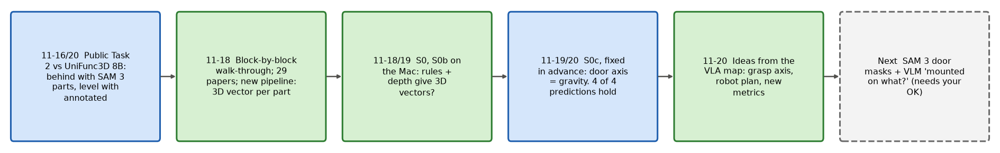

In [2]:
# the week's path, one box per step (done / tested / not built)
import textwrap

from matplotlib.patches import FancyBboxPatch

STEPS = [("11-16/20  Public Task 2 vs UniFunc3D 8B: behind with SAM 3 parts, level with annotated", "tested"),
         ("11-18  Block-by-block walk-through; 29 papers; new pipeline: 3D vector per part", "done"),
         ("11-18/19  S0, S0b on the Mac: rules + depth give 3D vectors?", "done"),
         ("11-19/20  S0c, fixed in advance: door axis = gravity. 4 of 4 predictions hold", "tested"),
         ("11-20  Ideas from the VLA map: grasp axis, robot plan, new metrics", "done"),
         ("Next  SAM 3 door masks + VLM 'mounted on what?' (needs your OK)", "next")]
STYLE = {"done": ("#d7f0d2", "#2e7d32"), "tested": ("#d5e6fb", "#1f5fae"), "next": ("#f3f3f3", "#6b6b6b")}
WIDTH, GAP, HEIGHT = 2.6, 0.4, 1.9
fig, axis = plt.subplots(figsize=(19, 3.0))
for i, (label, status) in enumerate(STEPS):
    x = i * (WIDTH + GAP)
    fill, edge = STYLE[status]
    axis.add_patch(FancyBboxPatch((x, 0), WIDTH, HEIGHT, boxstyle="round,pad=0.05", fc=fill, ec=edge, lw=2.2,
                                  ls="--" if status == "next" else "-"))
    axis.text(x + WIDTH / 2, HEIGHT / 2, textwrap.fill(label, 21), ha="center", va="center", fontsize=11.5, linespacing=1.25)
    if i < len(STEPS) - 1:
        axis.annotate("", xy=(x + WIDTH + GAP - 0.04, HEIGHT / 2), xytext=(x + WIDTH + 0.04, HEIGHT / 2),
                      arrowprops={"arrowstyle": "-|>", "color": "#52514e", "lw": 1.8})
axis.set_xlim(-0.15, len(STEPS) * (WIDTH + GAP) - GAP + 0.15)
axis.set_ylim(-0.15, HEIGHT + 0.15)
axis.axis("off")
fig.tight_layout()
display(fig)
plt.close(fig)

---
# 1. 先看演示

## 1.1 视频一：记忆贴在整段视频上（场景 421069，厨房和客厅）

**这是什么：** 手机在房子里走一圈的原始视频，一共 1025 帧。
- **橙色**是记忆里存的向量。规则从 40 张关键帧的 LiDAR 深度算出来，只算一次、存一次。
- **绿色**是标注。
- **线**表示转轴，**箭头**表示推拉方向。

**看点：** 镜头怎么动，向量都留在原来的部件上。因为它们存在三维世界坐标里，不是存在某一张图上。这就是"写一次，从哪个角度都能读"。

**要注意的地方：**
- **这是演示，不是检验。** 规则是 S0c 之后定的，而这个场景 S0 已经用过。检验看第 3 节的 S0c。
- **部件掩码用的是标注（ORACLE）。**
- **画到画面上用的是数据集里和扫描对齐的相机**，只为画得准。记忆本身用的是手机自己的位姿和 LiDAR。
- **有的橙、绿箭头方向相反**（比如插座）：标注里"往里还是往外"不统一，所以打分只比直线，不比方向。
- **烤箱门往下翻，轴是水平的。** 只看标签和深度，规则分不出它是门还是抽屉，也不知道轴是水平的。这正是"要问它装在什么上"的例子。

In [3]:
display(Video(str(ASSETS / "week2_walkthrough_421069.mp4"), embed=True, width=540, html_attributes="controls loop muted playsinline"))
w = media["walkthrough"]
print(f"{w['frames']} frames; at least one memory part in view in {w['frames_with_parts']} of them")

1025 frames; at least one memory part in view in 530 of them


## 1.2 视频二：三维的记忆（同一个场景）

**这是什么：** 这个场景的激光扫描点云，去掉了天花板，镜头在上方绕一圈。每个部件一个橙点和它的向量，绿色是标注；被墙挡住的部件不画。

**看点：** 记忆就是一张"部件表"，这是它在三维里的样子。每一条都能画出来、能检查：哪里碰、往哪动、绕哪根轴。

In [4]:
display(Video(str(ASSETS / "week2_memory_orbit_421069.mp4"), embed=True, width=720, html_attributes="controls loop muted playsinline"))
o = media["orbit"]
print(f"{o['frames']} frames, {o['points']:,} scan points; median {o['parts_drawn_median']:.0f} of {media['parts']} parts in view")

180 frames, 5,272,084 scan points; median 12 of 29 parts in view


## 1.3 图：事先定好预测的检验 S0c（场景 466437，卧室）

这一张来自正式检验 S0c：规则在跑之前就定好了，场景也是事先按规则选的，这个场景以前没用过。

- **上中的房门：** 橙色的轴是竖直的，和标注的门轴几乎重合。门轴取重力方向，这一步修好了。
- **右下的衣柜门：** 轴的方向对了，但橙色的轴画在把手旁边，真门轴在门的另一边。这是"门轴在哪里"的问题，靠深度找不准门板的边。
- **上右、下中的抽屉：** 被几何判断当成了门，画成了竖直轴。错在第一步"门还是抽屉"，不在轴。

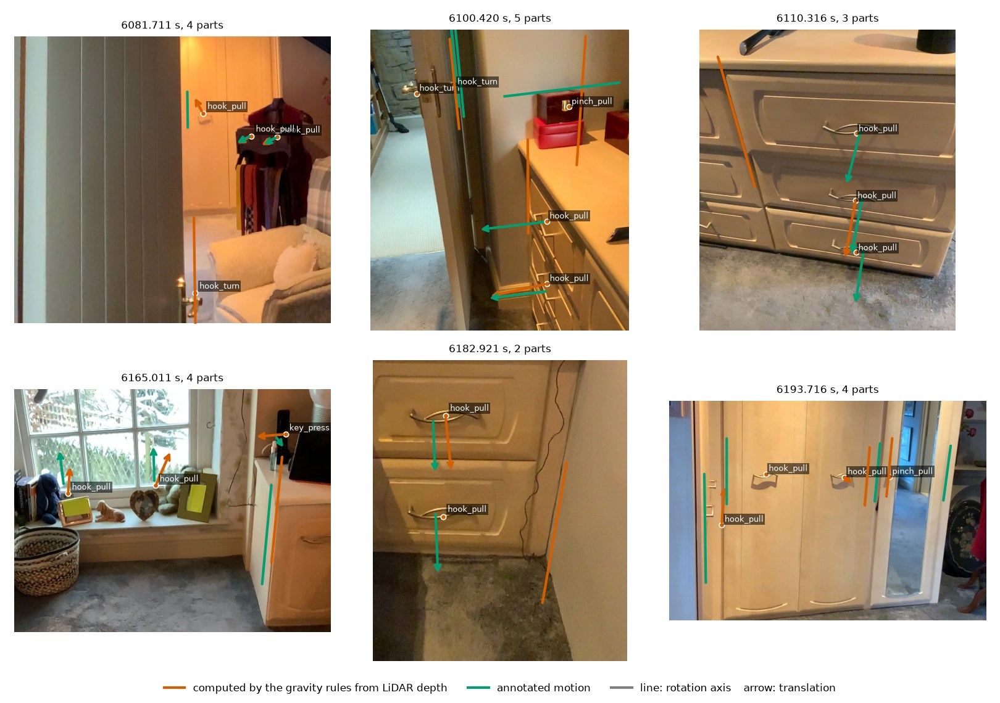

In [5]:
display(Image(filename=str(FIG / "s0c_2026-11-19" / "keyframes_466437.jpg"), width=1000))

## 1.4 图：门多的场景 S0b（场景 422842）

S0b 特意挑了门多的场景。衣柜门上，旧规则多数画成往外拉的箭头（当成抽屉），而标注是竖直的门轴。门轴"大多是竖直的"这条规律就是在这里事后看出来的，然后在 S0c 上事先定好再检验。

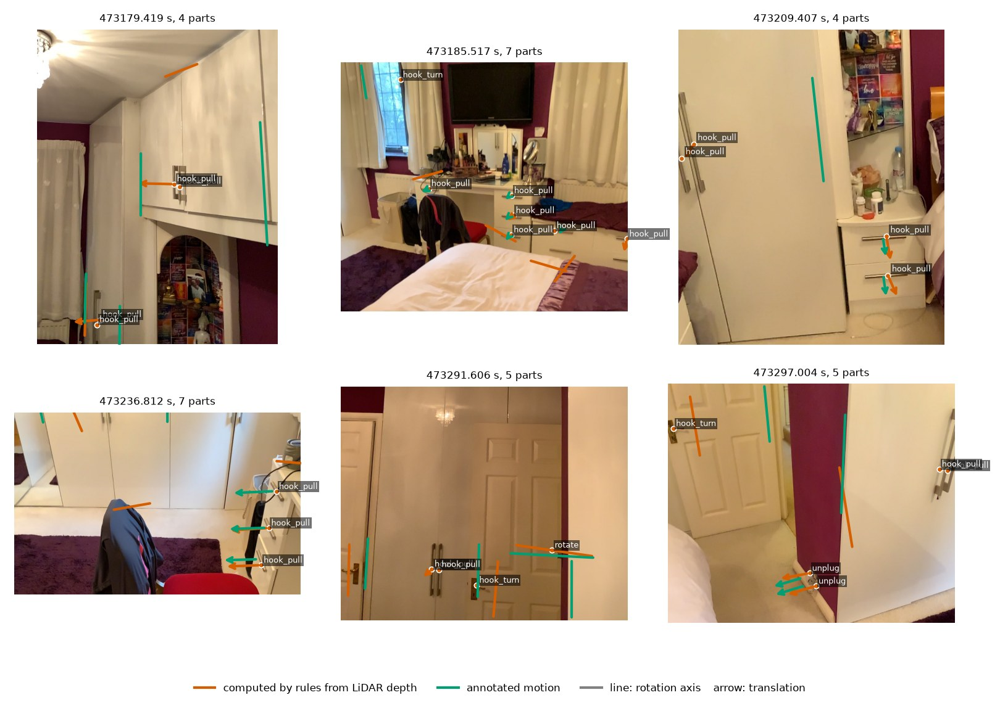

In [6]:
display(Image(filename=str(FIG / "s0b_2026-11-19" / "keyframes_422842.jpg"), width=1000))

## 1.5 图：机器人拿到记忆会怎么做（场景 421069）

把每条向量变成"手碰到的那一点会怎么走"：
- 推拉的部件：沿方向走 30 cm；
- 绕轴转的部件：绕轴转 60°；
- 旋钮：原地转一圈。

橙色是按记忆里的向量走，绿色是按标注走。每类部件挑两个，挑法是事先定的（出现在最多关键帧里的两个），不看结果好坏，所以对的和错的都有。每张小图的标题写了类型和轴对不对。

往哪边转、往外还是往里，标注里不统一，所以两条路径都按同一条规则定方向：一开始离开表面；按的部件往里。

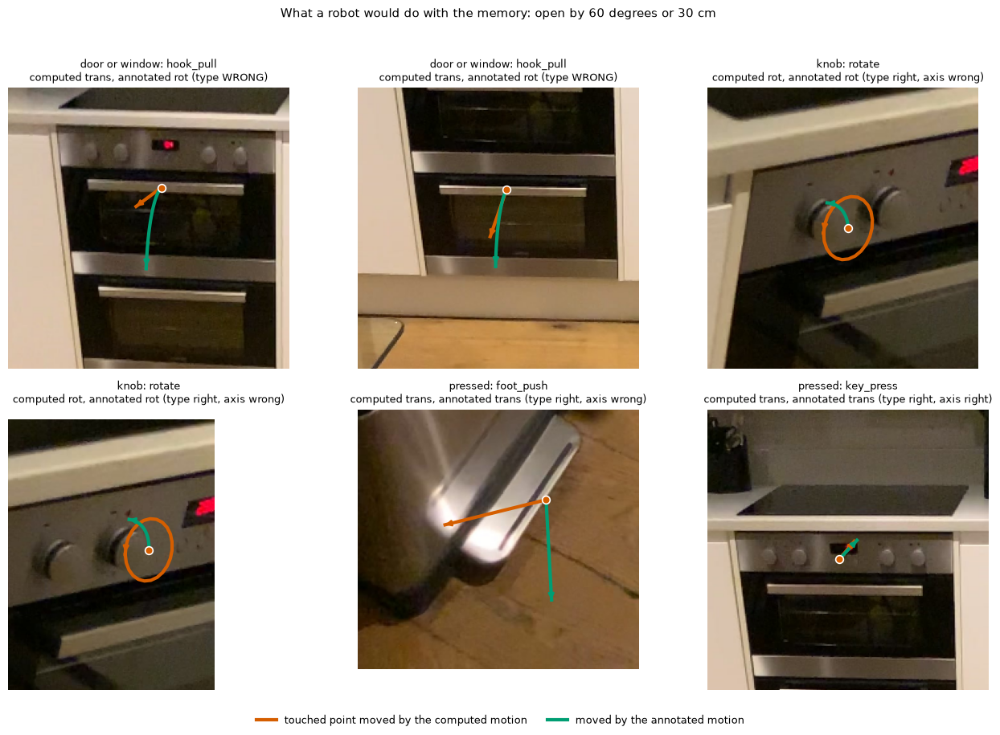

door or window  part   7  hook_pull   task: Open the top oven door
door or window  part   8  hook_pull   task: Open the bottom oven door
knob            part   4  rotate      task: 
knob            part   5  rotate      task: 
pressed         part  25  foot_push   task: Open the trash can located in the kitchen near the sink
pressed         part  21  key_press   task: 


In [7]:
examples = H.pick_examples(demo_rows, truths, DEMO["main"])
fig = H.motion_paths_figure(examples, truths, frames["lidar"])
display(fig)
plt.close(fig)
for name, row in examples:
    print(f"{name:15s} part {row['part']:3d}  {row['label']:10s}  task: {row['task'][:70]}")

---
# 2. 推荐的 pipeline（v3）和逐块讲解

## 2.1 pipeline 图

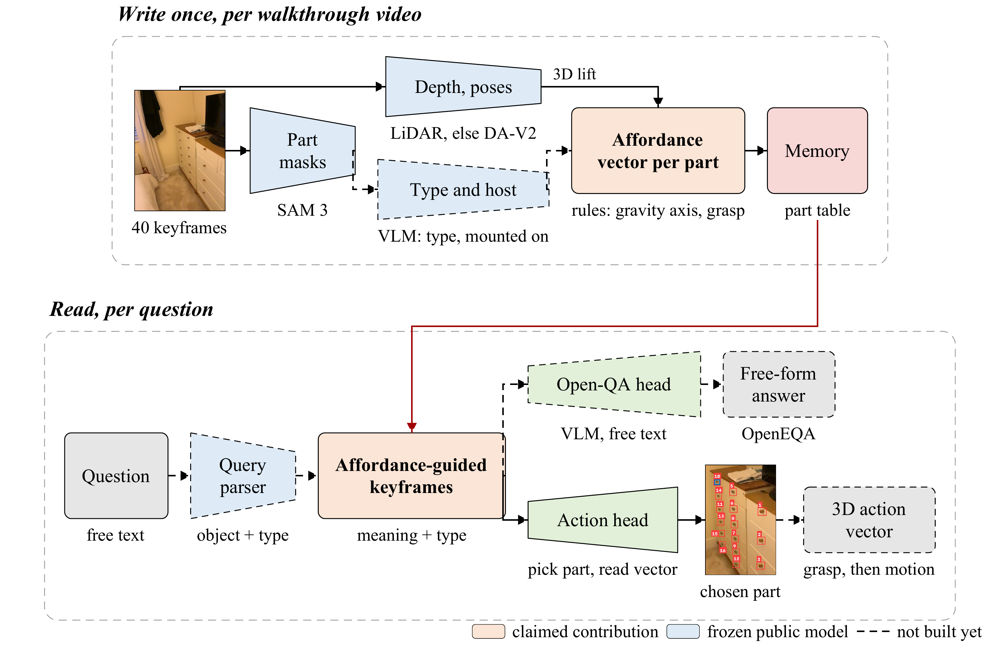

In [8]:
display(Image(filename=str(FIG / "proposal_2026-11-18" / "proposal_v3.png"), width=1000))

**怎么看这张图：**
- **上半部分是写入**，每段视频做一次：关键帧 → 部件掩码 → 每个部件的类型和"装在什么上" → 加上深度和位姿，算出每个部件的 affordance 向量 → 存进记忆（部件表）。
- **下半部分是读取**，每个问题做一次：问题 → 拆出物体和动作类型 → 按功能挑关键帧 → 两个头读同一份记忆。
  - 问答头：给自由文字回答，用 OpenEQA 评。
  - 动作头：选出部件，读出它的向量，交给机器人。先告诉它"抓哪里、怎么抓"，再告诉它"抓住以后怎么动"，用 SceneFun3D 评。
- **颜色：** 橙色是论文要主张的部分；蓝色是直接拿来用、不训练的公开模型；绿色是两个头；红线是记忆被读取的路径。
- **虚线：** 还没做的部分。

**和上周五的 v2 比，这周改了三处：**
1. 类型那一步写明还要问"装在什么上"（门、抽屉、面板）；
2. 向量的规则写明门轴取重力方向，并加了抓握轴；
3. 动作头的输出写明是"先抓、再动"。

源文件：`docs/mem/figures/proposal_2026-11-18/proposal_v3.yaml`（cvpr-figure 格式），另有 svg、pdf、pptx。

## 2.2 每一块现在是什么状态

| 块 | 做什么 | 用什么 | 现在 | 这一周的证据 |
| --- | --- | --- | --- | --- |
| W1 关键帧 | 从视频里挑 40 张最稳的画面 | 位姿和画面清晰度 | 有 | 漏掉 15% 到 21% 的部件 |
| W2 部件掩码 | 把能操作的小部件分出来 | SAM 3 | 有；本周的检验用标注代替 | 上周：SAM 3 找到 74.8% |
| W3 深度和位姿 | 每个像素多远、相机在哪 | 手机的 LiDAR 和位姿 | 有 | LiDAR 和渲染深度差不多；少数部件没有 LiDAR 深度 |
| W4 类型和所装的东西 | 推、拉、转；装在门、抽屉还是面板上 | 标签 + VLM | 类型有（来自标注的标签）；"装在什么上"没做 | 只看标签最多对 80% |
| W5 affordance 向量 | 接触点、法线、类型、轴、原点 | 规则 | 原型有 | S0、S0b、S0c |
| 记忆 | 部件表 | — | 有 | — |
| R1 问题解析 | 拆出物体和动作类型 | 大语言模型 | 没做 | — |
| R2 挑关键帧 | 按语义和类型挑 | SigLIP 2 + 部件表 | 部分有 | 上周 |
| R3b 动作头 | 选部件、读出向量 | Qwen3-VL-8B | 选部件有，读向量新 | 公开评测（第 3.4 节） |
| R3a 问答头 | 自由回答 | VLM | 没做 | — |

下面一块一块讲。例子都来自场景 421069 的真实数据，图上英文标注写明了哪些是标注（ORACLE）、哪些是上限。

## 2.3 W1 关键帧

**做什么：** 一段视频有上千帧，记忆只存在其中 40 张上。挑的是最稳的帧：相机转得慢、画面不糊。

**输入 → 输出：** 整段视频和每帧的位姿 → 40 张关键帧（图像、深度、相机）。

**这一周的发现：** 关键帧里一次都没出现的部件，记忆里就没有。三个检验里，这样的部件占 15% 到 21%（见下面的数）。用向量帮忙挑关键帧（你的 M2）之前，要先保证关键帧能覆盖部件。

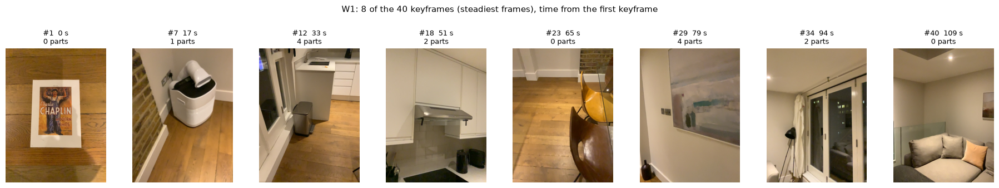

s0_421069          parts  38, never in the 40 keyframes  8 (21%)
s0b_val3           parts 110, never in the 40 keyframes 20 (18%)
s0c_gravity_val3   parts  80, never in the 40 keyframes 12 (15%)


In [9]:
fig = H.keyframe_strip(frames["lidar"], labels, times)
display(fig)
plt.close(fig)
for name in ("s0_421069", "s0b_val3", "s0c_gravity_val3"):
    c = H.run_json(name)["counts"]
    print(f"{name:18s} parts {c['elements']:3d}, never in the 40 keyframes {c['not_seen']:2d} ({100 * c['not_seen'] / c['elements']:.0f}%)")

## 2.4 W2 部件掩码

**做什么：** 在每张关键帧上，把能操作的小部件（拉手、旋钮、开关、插座……）分出来。

**用什么：** SAM 3。给它一个词，比如 handle，它就在图里把对应的东西框出来、分出来。

**现在的状态：**
- 上周在 30 个场景上，SAM 3 在 40 张关键帧里找到了 74.8% 的部件。
- 这一周的向量检验用的是**标注的掩码**（ORACLE，下图左边两张）。这样只检验"有了部件以后，向量算得对不对"，不把部件漏检的误差混进来。
- 再下面一张是上周 pipeline 的真实例子（场景 421254）：SAM 3 找到的部件编上号，让模型选；蓝框是模型选的。

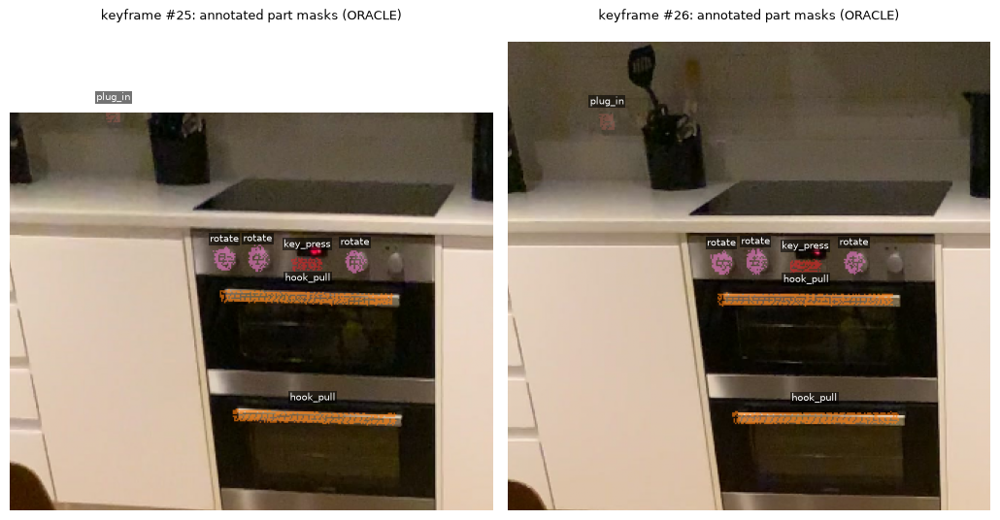

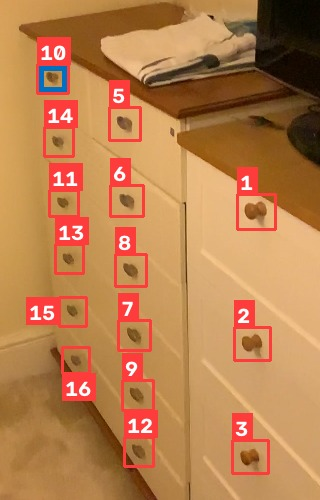

scene 421254 (week-1 pipeline): SAM 3 parts, numbered for the model; blue = the box the 8B model picked


In [10]:
picks = sorted(range(len(labels)), key=lambda k: -int((labels[k] >= 0).sum()))[:2]  # the two keyframes with the most part pixels
fig = H.masks_figure(scene, frames["lidar"], labels, sorted(picks))
display(fig)
plt.close(fig)
display(Image(filename=str(FIG / "pipeline" / "pipeline_answer_zoom.jpg"), width=300))
print("scene 421254 (week-1 pipeline): SAM 3 parts, numbered for the model; blue = the box the 8B model picked")

## 2.5 W3 深度和位姿

**做什么：** 知道每个像素离相机多远、相机在世界里的哪里。有了这两样，图上的一个点就能变成世界里的一个三维点。

**用什么：** 手机自带的 LiDAR 深度和 ARKit 位姿，都是设备直接给的，不用模型。没有 LiDAR 的设备再用单目深度模型（Depth Anything V2）。

**这一周的发现：**
- LiDAR 和"从激光扫描渲染出的深度"（上限）算出的向量差不多好，所以推荐 LiDAR 优先。
- 但少数部件没有 LiDAR 深度：玻璃、很细的把手、太远的地方。下图中间，白圈标出这一帧里没有 LiDAR 深度的部件。

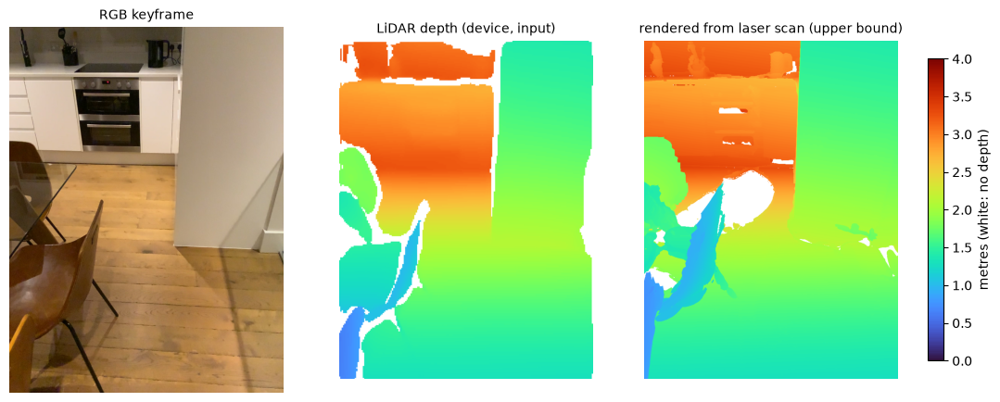

keyframe #26: 0 of 7 parts have no LiDAR depth at any pixel
s0b_val3           7 of 89 scored parts without a LiDAR vector
s0c_gravity_val3   6 of 64 scored parts without a LiDAR vector


In [11]:
k = max(range(len(labels)), key=lambda k: int((labels[k] >= 0).sum()))  # the keyframe with the most part pixels
fig, blind, total = H.depth_figure(frames["lidar"][k], frames["rendered"][k], labels[k])
display(fig)
plt.close(fig)
print(f"keyframe #{k + 1}: {blind} of {total} parts have no LiDAR depth at any pixel")
for name, visits in (("s0b_val3", ("422842", "467115", "466916")), ("s0c_gravity_val3", ("466880", "466437", "466841"))):
    rows = [r for v in visits for r in H.run_json(f"{name}/{v}", "parts.json") if (r["depth"], r["rule"], r["frames"]) == ("lidar", "c1", "best")]
    print(f"{name:18s} {sum(r['vector'] is None for r in rows)} of {len(rows)} scored parts without a LiDAR vector")

## 2.6 W4 动作类型和"装在什么上"

**做什么：** 判断每个部件是推、拉还是转，并且它装在什么上：门、抽屉、固定的面板，还是烤箱门、翻盖。

**为什么要问"装在什么上"：** 下图是 30 个验证场景里所有有运动标注的部件。9 类标签里有 7 类，看标签就知道是平移还是转动。但两类"拉"不行：勾着拉的有将近一半是门（转动），捏着拉的约三成是门。所以：
- 只看标签，运动类型最多对 80%；
- 靠几何猜（看拉手在门面上偏不偏），在抽屉多的房间里反而更差（第 3.3 节）；
- 所以要问一句"这个拉手装在什么上"。

**现在的状态：** 类型来自标注的标签；"装在什么上"还没做，是下一步要在服务器上做的检验（第 4 节决定 1）。

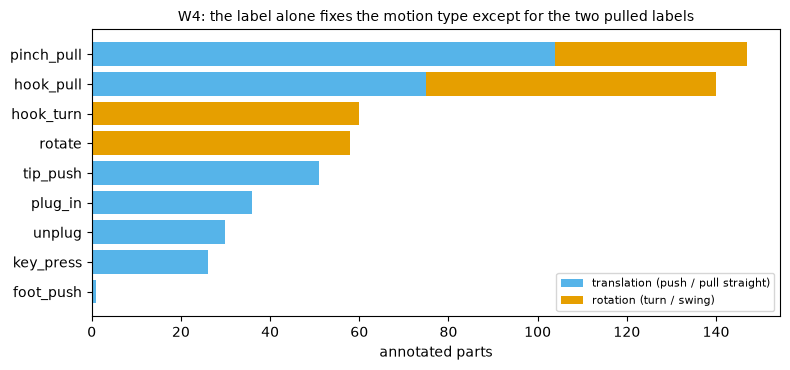

30 scenes, 549 parts; label-only motion type at best 441/549 = 80.3%


In [12]:
visits = (ROOT / "third_party" / "scenefun3d" / "benchmark_file_lists" / "val_scenes.txt").read_text().split()
pairs = Counter(pair for visit in visits for pair in CLM.label_motions(ROOT / "data" / "scenefun3d", visit))
fig = H.label_motion_figure(pairs)
display(fig)
plt.close(fig)
best = sum(max(pairs[(l, "trans")], pairs[(l, "rot")]) for l in {l for l, _ in pairs})
print(f"{len(visits)} scenes, {sum(pairs.values())} parts; label-only motion type at best {best}/{sum(pairs.values())} = {100 * best / sum(pairs.values()):.1f}%")

## 2.7 W5 每个部件的 affordance 向量

**做什么：** 给每个部件算一条三维向量，存进记忆。现在存的字段：

| 字段 | 意思 | 怎么算 |
| --- | --- | --- |
| 接触点 | 手碰的那个点（x, y, z） | 部件掩码中心的像素 + 深度 + 位姿 |
| 法线 | 接触面朝哪边 | 部件周围的深度拟合一个平面 |
| 类型 | 平移还是转动 | 现在：标签（+ 几何判断门还是抽屉）；以后：问"装在什么上" |
| 方向或转轴 | 推拉的方向，或转轴的方向；存成没有正负号的线 | 按的：沿法线往里；拉的：往外；旋钮：轴 = 法线；门窗：轴 = 重力方向 |
| 原点 | 转轴经过的点 | 旋钮：接触点；门窗：门面水平方向上离把手远的那一端（临时，以后用门板掩码） |
| 证据帧 | 哪些关键帧看得到它 | 写入时记下 |

**计划加的字段（11-20 对照 VLA 的 map 后加的，还没实现）：** 接近方向（法线反过来）、抓握轴（手指闭合的方向，主要对长条把手有用）、接触区域（部件的一片点和分数）。

**为什么说它看得懂：** 每个字段都能直接画出来（第 1 节的视频和图就是这样画的）。错了也能看出错在哪：类型错了、点偏了，还是轴歪了。

下面是记忆里这个场景的部件表（前 12 行）。坐标在设备的世界坐标里（ARKit，z 朝上，单位米）；接给机器人时，只要再乘一个刚体变换。

In [13]:
display(H.part_table_frame("demo_421069_gravity"))

,标签,任务（标注里的描述）,类型,接触点 (m),法线,方向或转轴,原点 (m),证据帧数
部件,,,,,,,,
0,hook_turn,Open the window located above the trash can in t,rot,"(+3.86, -1.86, +0.73)","(-0.87, +0.47, +0.16)","(-0.00, +0.00, +1.00)","(+3.80, -1.93, +0.73)",2
1,hook_turn,Open the right balcony door located in the kitch,rot,"(+5.07, -2.84, +0.38)","(+0.47, +0.16, +0.86)","(-0.00, +0.00, +1.00)","(+5.07, -2.84, +0.38)",1
2,hook_turn,Open the left balcony door located in the kitche,rot,"(+3.83, -1.01, +0.75)","(-0.99, +0.15, -0.03)","(-0.00, +0.00, +1.00)","(+3.81, -1.09, +0.74)",2
3,hook_turn,Open the small window located near to the portab,rot,"(+3.83, -0.28, +0.70)","(-0.76, -0.13, +0.63)","(-0.00, +0.00, +1.00)","(+3.83, -0.59, +0.61)",2
4,rotate,,rot,"(+2.10, -2.89, +0.32)","(+0.07, +0.95, +0.29)","(+0.07, +0.95, +0.29)","(+2.10, -2.89, +0.32)",3
5,rotate,,rot,"(+2.02, -2.89, +0.32)","(+0.07, +0.91, +0.41)","(+0.07, +0.91, +0.41)","(+2.02, -2.89, +0.32)",3
6,rotate,,rot,"(+1.83, -2.92, +0.35)","(-0.02, +1.00, -0.03)","(-0.02, +1.00, -0.03)","(+1.83, -2.92, +0.35)",2
7,hook_pull,Open the top oven door,trans,"(+1.94, -2.90, +0.26)","(+0.02, +1.00, +0.06)","(+0.02, +1.00, +0.06)","(+1.94, -2.90, +0.26)",3
8,hook_pull,Open the bottom oven door,trans,"(+1.95, -2.89, -0.02)","(-0.01, +0.99, -0.11)","(-0.01, +0.99, -0.11)","(+1.95, -2.89, -0.02)",3


## 2.8 读取：R1 问题解析、R2 挑关键帧、R3 两个头

这一周没有改读取这一侧，状态如下：

- **R1 问题解析（没做）：** 从问题里拆出物体、部件、想要的动作类型。打算用现成的大语言模型，和 Fun3DU、UniFunc3D 一样。
- **R2 按功能挑关键帧（部分有）：** 关键帧得分 = 语义相似度 + 部件得分。上周的结果：在标注的部件图上，第一张就挑对的比例，按功能存是 66%，只按整张画面是 46%。
- **R3b 动作头（选部件有，读向量是新的）：** 模型在编号框里选一个部件，再从部件表里读出它的向量。例子就是 W2 里那张图：任务是"打开电视左边柜子左上角的抽屉"，8B 模型选了 10 号（蓝框），选对了。公开评测（第 3.4 节）评的就是"选部件"这一步。
- **R3a 问答头（没做）：** 给模型看挑出的关键帧和每个编号一行简短记录，让它自由回答。计划加一项检验：故意改一条记忆，看回答跟不跟着变，确认它在用记忆。

---
# 3. 这一周的结果

## 3.1 规则算出的三维向量：S0、S0b、S0c

三个检验问的是同一个问题：**有了部件掩码（标注）以后，规则加深度能不能算出对的三维向量？** 都只用 CPU，每个不到一分钟。

| 检验 | 场景 | 做法 |
| --- | --- | --- |
| S0 | 421069（1 个） | 第一次试：规则行不行 |
| S0b | 422842、467115、466916（门最多的 3 个验证场景，事先按规则选） | 换场景看 S0 的结论还成不成立；事后诊断门窗错在哪 |
| S0c | 466880、466437、466841（门第 4 到第 6 多的验证场景，事先选） | 检验事后看出的"门轴竖直"：规则和预测在跑之前提交 |

**怎么读下面的表：** 每格是三个百分比，"+M / +MA / +MAO"：
- **+M**：运动类型（平移还是转动）对了；
- **+MA**：类型对，并且轴或方向和真值的夹角在 15° 以内（只比直线，不比正反）；
- **+MAO**：再加上转动的原点离真轴不到 0.25 m（平移没有原点，这一项同 +MA）。

这是 SceneFun3D Task 3 论文里的定义。下面都是 LiDAR 深度、每个部件用画面最大的一帧。

列的意思：
- **c1**：只看标签；
- **geometric**：标签，再加上按拉手在门面上的位置猜门还是抽屉；
- **gravity**：geometric，但门轴取重力方向（S0c 新加）；
- **oracle**（类型给对）：用标注的运动类型。真实系统里没有它，用来看"类型对了以后，几何算得准不准"。

In [14]:
BASE = {"c1": "lidar/c1/best", "geometric": "lidar/geometric/best", "oracle_kind": "lidar/oracle_kind/best"}
NEW = {"c1": "lidar/c1/best", "geometric": "lidar/geometric/best", "gravity（新）": "lidar/gravity/best",
       "oracle_kind": "lidar/oracle_kind/best", "oracle_gravity（新）": "lidar/oracle_gravity/best"}
for title, name, variants in (("S0：场景 421069", "s0_421069", BASE), ("S0b：3 个门多的验证场景（合并）", "s0b_val3", BASE),
                              ("S0c：3 个新的验证场景（合并）", "s0c_gravity_val3", NEW)):
    print(title)
    display(H.rates_table(name, variants))

S0：场景 421069


,个数,c1,geometric,oracle_kind
部件,,,,
按、插的部件,10,100 / 60 / 60,100 / 60 / 60,100 / 60 / 60
旋钮,11,100 / 54 / 54,100 / 54 / 54,100 / 54 / 54
门窗类（轴在部件外）,8,50 / 25 / 0,62 / 25 / 0,100 / 62 / 12
全部,29,86 / 48 / 41,90 / 48 / 41,100 / 59 / 45


S0b：3 个门多的验证场景（合并）


,个数,c1,geometric,oracle_kind
部件,,,,
按、插的部件,17,94 / 53 / 53,94 / 53 / 53,94 / 53 / 53
旋钮,6,67 / 33 / 33,67 / 33 / 33,67 / 33 / 33
门窗类（轴在部件外）,44,7 / 7 / 0,36 / 18 / 9,93 / 54 / 20
全部,89,49 / 34 / 30,54 / 33 / 28,92 / 57 / 40


S0c：3 个新的验证场景（合并）


,个数,c1,geometric,gravity（新）,oracle_kind,oracle_gravity（新）
部件,,,,,,
按、插的部件,6,100 / 83 / 83,100 / 83 / 83,100 / 83 / 83,100 / 83 / 83,100 / 83 / 83
旋钮,3,67 / 0 / 0,67 / 0 / 0,67 / 0 / 0,67 / 0 / 0,67 / 0 / 0
门窗类（轴在部件外）,19,37 / 37 / 5,74 / 58 / 10,74 / 63 / 10,95 / 68 / 16,95 / 84 / 21
全部,64,73 / 61 / 52,67 / 50 / 36,67 / 52 / 36,91 / 70 / 55,91 / 75 / 56


**读法：**
1. **按、插的部件：** 三轮都在一半到八成之间。规则加深度对这类部件够用。
2. **旋钮：** 很差，因为旋钮周围的表面法线估不准（旋钮很小，周围常是斜面或曲面）。
3. **门窗类：** 只看标签几乎全错，因为"拉"在标签里分不出门和抽屉。类型给对以后，S0c 的新规则（oracle_gravity）把 +MA 从 68% 提到 84%，但 +MAO 只有 21%：门轴的位置还是找不准。
4. **全部部件：** S0c 里 geometric 的 +M 比只看标签还低，原因见 3.3。

## 3.2 S0c：事先写好的四条预测

预测和采用规则写在 `configs/part_vectors/s0c_gravity_val3.yaml` 里，在运行前提交（提交 9cd8daf）。下面的数直接从结果文件读出来。

In [15]:
s0c = H.run_json("s0c_gravity_val3")
doors = H.run_json("s0c_gravity_val3", "door_hinges.json")["counts"]["lidar"]
off = {rule: s0c["variants"][f"lidar/{rule}/best"]["off_part_rotations"] for rule in ("oracle_kind", "oracle_gravity")}
rows_c = [r for v in ("466880", "466437", "466841") for r in H.run_json(f"s0c_gravity_val3/{v}", "parts.json")]
key = lambda r: (r["visit"], r["depth"], r["frames"], r["part"])
by_rule = {rule: {key(r): r for r in rows_c if r["rule"] == rule} for rule in ("geometric", "gravity", "oracle_kind", "oracle_gravity")}
checked = differ = 0
for a_rule, b_rule in (("geometric", "gravity"), ("oracle_kind", "oracle_gravity")):
    for k, a in by_rule[a_rule].items():
        b = by_rule[b_rule][k]
        if a["label"] not in ("hook_pull", "pinch_pull", "hook_turn") or b["vector"] is None or b["vector"]["kind"] != "rot":
            checked, differ = checked + 1, differ + (a["score"] != b["score"])
p1 = 100 * doors["true_axis_vertical"] / doors["doors"]
p2 = off["oracle_gravity"]["ma"] - off["oracle_kind"]["ma"]
predictions = pd.DataFrame([
    ("P1", "真轴至少 80% 是竖直的", f"{doors['true_axis_vertical']}/{doors['doors']} = {p1:.0f}%", p1 >= 80),
    ("P2", "轴：oracle_gravity 的 +MA 比 oracle_kind 高至少 15 个点",
     f"{off['oracle_gravity']['ma']:.0f}% 对 {off['oracle_kind']['ma']:.0f}%，高 {p2:.1f} 个点", p2 >= 15),
    ("P3", "原点：oracle_gravity 的 +MAO 不低于 oracle_kind", f"{off['oracle_gravity']['mao']:.0f}% 对 {off['oracle_kind']['mao']:.0f}%",
     off["oracle_gravity"]["mao"] >= off["oracle_kind"]["mao"]),
    ("P4", "别的部件分数不变（构造上的检查）", f"{checked} 次比较，{differ} 处不同", differ == 0),
], columns=["编号", "预测", "结果", "成立"]).set_index("编号")
display(predictions)

,预测,结果,成立
编号,,,
P1,真轴至少 80% 是竖直的,16/19 = 84%,True
P2,轴：oracle_gravity 的 +MA 比 oracle_kind 高至少 15 个点,84% 对 68%，高 15.8 个点,True
P3,原点：oracle_gravity 的 +MAO 不低于 oracle_kind,21% 对 16%,True
P4,别的部件分数不变（构造上的检查）,330 次比较，0 处不同,True


**结论：** 四条都成立，其中 P1、P2 刚好过线（P2 只差 3 个部件）。按事先定的规则，"门轴 = 重力方向"写进了推荐 pipeline。"原点 = 门面远端"也按规则写进去了，但标成临时：4 个对的原点里，只有 2 个来自"门面远端"。

## 3.3 门窗：错在哪一步

左边是 S0b（事后诊断），右边是 S0c（新场景）。对每个门窗类部件，比较四种定门轴的办法：
- 旧规则：门面的边；
- 竖直轴，过把手；
- 竖直轴，过门面远端；
- 竖直轴，过两端里对的那一端：相当于告诉它门轴在哪一边，是这类办法的上限。

蓝色是"轴对"，橙色是"轴和原点都对"。

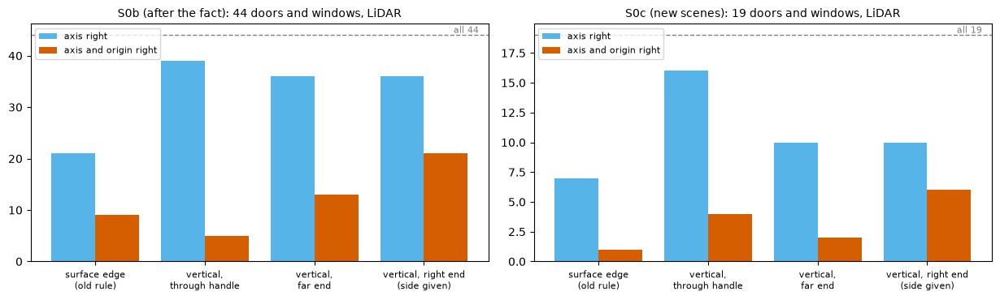

S0c drawers, rule c1       : type right 31 of 35
S0c drawers, rule geometric: type right 20 of 35


In [16]:
fig = H.doors_figure({"S0b (after the fact)": "s0b_val3", "S0c (new scenes)": "s0c_gravity_val3"})
display(fig)
plt.close(fig)
drawer = lambda r: r["label"] in ("hook_pull", "pinch_pull") and r["true_kind"] == "trans"
for rule in ("c1", "geometric"):
    mine = [r for r in rows_c if (r["depth"], r["rule"], r["frames"]) == ("lidar", rule, "best") and drawer(r)]
    print(f"S0c drawers, rule {rule:9s}: type right {sum(r['score']['m'] for r in mine)} of {len(mine)}")

**门窗的问题拆成三步，难度不一样：**
1. **门还是抽屉（类型）：** 只看标签最多对 80%。靠几何猜，在 S0b（门多）里有帮助，在 S0c（抽屉多）里反而把 11 个抽屉当成了门（上面最后两行）。所以要问"装在什么上"。
2. **门轴方向：** 用重力方向就修好了，两轮里大多数门轴都是竖直的。例外是烤箱门、翻盖这类水平轴，也要靠"装在什么上"来区分。
3. **门轴位置（原点）：** 最难。就算告诉它门轴在哪一边，也只对一半（S0b）到三分之一（S0c）。原因是靠深度找门面的边找早了：测到的门面宽度中位数只有约 0.3 m，比真门窄。要把整块门板分出来（SAM 3 门板掩码），这是下一步。

## 3.4 公开评测：SceneFun3D Task 2，和 UniFunc3D 8B 比（445 条任务）

**测的是什么：** 上周的 pipeline 能不能在公开协议下"指出要操作的部件"。流程是：
1. SAM 3 建记忆；
2. 挑 3 张关键帧；
3. Qwen3-VL-8B 在编号框里选一个部件；
4. SAM 3 把选中的部件分出来；
5. 投到激光扫描上，变成扫描上的点集，和标注比。

**比的对象是 UniFunc3D 8B：** 同样大小的模型，每个问题看 64 帧。用他们公开的预测和我们同一套打分代码比。怎么读在跑之前就写定了（讨论稿 27.2）。

**这一周做了什么：** GPU 那一步 11-17 走队列跑完；这周五补完了"投到扫描上"和"打分"两步，只用 CPU。

**指标：** AP25 是"预测的点集和标注重合够多（IoU 至少 0.25）"的比例；mIoU 是平均重合度。都是百分比，越高越好。

In [17]:
PE = ROOT / "runs" / "public_eval" / "public_eval_split0_8b"
pe = json.loads((PE / "summary.json").read_text())
cmp = {p.stem: json.loads(p.read_text()) for p in sorted((PE / "compare").glob("*.json"))}
METRICS = ("AP25", "mIoU", "AP50", "mAP")
ARMS = {"p4t_sam3": "记忆，SAM 3 建的部件图（P4，主要的一组）", "c3": "模型直接看 40 张均匀帧（c3）", "sam3q": "用任务文字直接提示 SAM 3",
        "p4n": "记忆，标注的部件图（上限）", "oracle_chosen": "投法上限：模型选的那一帧上，完美的掩码", "oracle_best": "投法上限：最好的那一帧上，完美的掩码"}
ref = cmp["p4t_sam3_vs_reference"]["first_minus_second"]
unifunc = {m: pe["means"]["p4t_sam3"][m] - ref[m]["rate"] for m in METRICS}  # the reference's own score, on the same tasks
rows = [{"组": name, **{m: round(pe["means"][arm][m], 1) for m in METRICS}} for arm, name in ARMS.items()]
rows.insert(1, {"组": "UniFunc3D 8B（他们公开的预测，我们的打分代码）", **{m: round(v, 1) for m, v in unifunc.items()}})
display(pd.DataFrame(rows).set_index("组"))

VERDICT = {"comparable": "相当", "behind": "落后", "clearly behind": "明显落后", "unclear": "说不清"}
PAIRS = {"p4t_sam3_vs_reference": "记忆（SAM 3）减 UniFunc3D 8B", "p4n_vs_reference": "记忆（标注部件图）减 UniFunc3D 8B",
         "p4t_sam3_vs_c3": "记忆（SAM 3）减 直接看原视频", "c3_vs_reference": "直接看原视频 减 UniFunc3D 8B",
         "sam3q_vs_reference": "直接提示 SAM 3 减 UniFunc3D 8B"}
diff = lambda d: f"{d['rate']:+.1f}（{d['low']:+.1f} 到 {d['high']:+.1f}）"
display(pd.DataFrame([{"成对比较（同样 445 条任务）": label, "AP25 差": diff(cmp[k]["first_minus_second"]["AP25"]),
                       "mIoU 差": diff(cmp[k]["first_minus_second"]["mIoU"]), "按事先的规则": VERDICT[cmp[k]["verdict"]]}
                      for k, label in PAIRS.items()]).set_index("成对比较（同样 445 条任务）"))
pe_checks = [check("P4 AP25", round(pe["means"]["p4t_sam3"]["AP25"], 1), 24.9), check("UniFunc3D 8B AP25", round(unifunc["AP25"], 1), 44.0),
             check("P4 minus UniFunc3D AP25", round(ref["AP25"]["rate"], 1), -19.1), check("p4n AP25", round(pe["means"]["p4n"]["AP25"], 1), 43.1),
             check("P4 minus c3 AP25", round(cmp["p4t_sam3_vs_c3"]["first_minus_second"]["AP25"]["rate"], 1), 5.6),
             check("oracle_best AP25", round(pe["means"]["oracle_best"]["AP25"], 1), 88.1)]
print(f"{len(pe_checks)} numbers of this section checked; differences in percentage points, 95% intervals from resampling the 30 scenes")

,AP25,mIoU,AP50,mAP
组,,,,
记忆，SAM 3 建的部件图（P4，主要的一组）,24.9,10.5,9.9,3.4
UniFunc3D 8B（他们公开的预测，我们的打分代码）,44.0,20.9,23.8,10.7
模型直接看 40 张均匀帧（c3）,19.3,9.9,7.2,2.4
用任务文字直接提示 SAM 3,5.4,2.6,2.7,0.9
记忆，标注的部件图（上限）,43.1,18.1,20.9,7.6
投法上限：模型选的那一帧上，完美的掩码,51.5,27.0,46.5,31.9
投法上限：最好的那一帧上，完美的掩码,88.1,45.2,72.8,43.4


,AP25 差,mIoU 差,按事先的规则
成对比较（同样 445 条任务）,,,
记忆（SAM 3）减 UniFunc3D 8B,-19.1（-25.9 到 -12.4）,-10.4（-14.2 到 -7.0）,明显落后
记忆（标注部件图）减 UniFunc3D 8B,-0.9（-7.0 到 +6.4）,-2.8（-5.8 到 +0.2）,说不清
记忆（SAM 3）减 直接看原视频,+5.6（+0.2 到 +11.0）,+0.6（-1.5 到 +2.8）,相当
直接看原视频 减 UniFunc3D 8B,-24.7（-29.8 到 -19.5）,-11.1（-13.7 到 -8.6）,明显落后
直接提示 SAM 3 减 UniFunc3D 8B,-38.7（-44.6 到 -32.5）,-18.3（-21.9 到 -14.6）,明显落后


6 numbers of this section checked; differences in percentage points, 95% intervals from resampling the 30 scenes


**读法（跑之前写定的）：**
- **记忆（SAM 3 部件图）比 UniFunc3D 8B 明显落后。** AP25 低 19.1 个点（区间 −25.9 到 −12.4），mIoU 低 10.4 个点（−14.2 到 −7.0）。两个区间都整个低于门槛（AP25 −10，mIoU −5），按规则是"明显落后"。规则说这时要停下来讨论：论文不能靠准确度，只能看代价站不站得住（第 4 节决定 5）。
- **差距主要在部件图。** 换成标注的部件图（上限），AP25 是 43.1，和 UniFunc3D 8B 的 44.0 分不出高低（差 −0.9，区间 −7.0 到 6.4）。SAM 3 只找到约四分之三的部件（74.8%），没找到的部件，后面再好也选不对。
- **投到扫描上这一步损失不大。** 如果在最好的那一帧上有完美的掩码，AP25 能到 88.1。
- **记忆比"直接看原视频"好一点。** AP25 高 5.6 个点（0.2 到 11.0），mIoU 差不多，按规则是"相当"。
- **官方打分器的参照分数没算出来。** 它检查一个任务时，发现我们导出的点数和标注对不上，报错停了。上面的数都来自和 UniFunc3D 相同的打分代码，不受影响；导出的问题下周修。

**这对新 pipeline 意味着什么：** 新 pipeline 的向量也要先有部件。S0 到 S0c 用的都是标注的部件掩码，而这里说明，部件用 SAM 3 自己找时，差距主要就出在这一步。Task 3 的打分也是先要定位对（AP25 之上再看运动），所以"部件找不找得到"是新 pipeline 绕不开的问题。

---
# 4. 主旨核对和需要你决定的事

## 4.1 主旨核对（这一周整体）

| 你的主旨 | 这一周 |
| --- | --- |
| M1 可解释的三维向量，能给机器人用 | **符合。** 每个部件一条三维向量，在世界坐标里，视频和点云里都能画出来（第 1 节）。下一步加抓握轴，每条记录就能解码成"抓哪里、怎么抓、抓住以后怎么动"。 |
| M2 用向量帮忙挑关键帧 | **还没测，有了方案。** 40 张关键帧漏掉 15% 到 21% 的部件，要先保证关键帧能覆盖部件。11-20 提出用三维表面 affordance map 按"哪一帧看得清"挑帧（决定 6）。 |
| M3 affordance 加深度算出动作向量 | **符合**，三轮检验测的就是这一步。但见下面第一条提醒。 |
| M4 两个头 | **部分。** 动作头的"选部件"在公开评测上评了（第 3.4 节）：用 SAM 3 的部件图时明显落后于 UniFunc3D 8B，用标注的部件图时和它差不多。读向量和问答头还没做。 |
| M5 现成模型加规则，不训练 | **符合。** 这一周全是规则和现成模型，没有训练。 |
| M6 用尽量少的资源 | **符合。** 向量检验每个不到一分钟 CPU；两个视频也只用 CPU；公开评测的 GPU 部分 11-17 走队列跑完，后两步只用 CPU。 |

**提醒：**
1. **偏移：只有 affordance 标签加深度不够。** 三轮检验都指向这一点：门还是抽屉，要知道拉手"装在什么上"。记忆里每个部件最好也存这一项，这会改变 affordance map 存什么（决定 2）。
2. **可能的理解差异："affordance map"可以指两种东西。** 一种是网络预测的逐像素稠密图（VLA 那边就是这种），一种是这边逐部件的记录。逐部件的记录需要时也能投影成逐像素的图（决定 3）。
3. **门窗的动作向量现在只有方向可靠，位置不可靠。** 机器人开门时，转动半径取决于门轴在哪里，要等门板掩码。
4. **这一周的向量检验都用标注的部件掩码。** 公开评测说明，部件由 SAM 3 自己找时，差距主要就出在这一步。

## 4.2 需要你决定的事（聊天里也会列）

1. **服务器上的下一步：用 SAM 3 门板掩码，再问 VLM"这个拉手装在什么上"，在 30 个验证场景上检验。** 要用 GPU，排队后不到 1 小时。
   - (a) 我先把方案写好给你看：场景、提问方式、打分方法、事先的预测。你确认后再排队。
   - (b) 写好方案就直接排队，排在你自己的 vid_tokenizer 作业前面。

   我推荐 **(a)**：这是第一个要用 VLM 回答"装在什么上"的检验，问法会直接影响结果。
2. **记忆里每个部件要不要也存"装在什么上"（门、抽屉、固定面板、烤箱门或翻盖）？**
   - (a) 存，affordance map 每个部件多一个字段。
   - (b) 不存。那样拉手的运动类型最多对 80%。

   我推荐 **(a)**。
3. **记忆里的 affordance map 用哪种形式？**
   - (a) 逐部件的记录（现在的做法），需要时投影成逐像素的图。不用训练。
   - (b) 由网络预测的逐像素稠密图。要训练。

   我推荐 **(a)**：M5 是先不训练；投影出来的图也能交给需要这种输入的下游。
4. **S0d 做不做：** 在 S0b、S0c 的 6 个场景上补算抓握轴和接触区域，加上接触点和失败归类的指标，重新打分。只用 CPU，几分钟。
   - (a) 做，放在服务器那一步之前。
   - (b) 不做，等服务器那一步时一起算。

   我推荐 **(a)**。

5. **公开评测"明显落后"以后怎么走？**（事先写定的读法要求停下来讨论，见第 3.4 节）
   - (a) 接受落后，不把 Task 2 的准确度当卖点，如实报告；继续新 pipeline。
   - (b) 先只用 CPU 看 SAM 3 漏掉的是哪些部件：按标签、大小、离相机多远分开数。用已有的结果，几分钟。再决定要不要花 GPU 补部件图。
   - (c) 直接花 GPU 补部件图（换提示词、多帧合并），争取追上。不训练。

   我推荐 **(b)**：不花 GPU，先弄清差在哪类部件。部件找不找得到，新 pipeline 也绕不开：Task 3 也要先定位对。

6. **affordance map 做成三维表面图吗？**（11-20 提出，读了 AROS 以后；目的是帮忙搜索目标，物体和动作的可能性都要能搜）
   - **做法：** 表面用关键帧的深度加位姿算出来（跑分时也可以用数据集给的激光扫描），每个表面点记住"哪些帧看见过它"。上面叠三层：
     - 几何层：朝向、高度、前面有没有空地，用规则判断；
     - 语义层：SAM 3 的掩码投到表面上，多帧投票；
     - 向量层：部件的动作向量挂到这个部件的点上。

     搜索时三层取交集，得到一小块三维掩码；再按"哪一帧看得清"挑帧，画到帧上给 VLM 看。
   - **已有的证据：** 阶段 1 把 40 张深度图融合以后读接触点，并没有更准（中位误差 5.4 cm，单帧 4.1 cm；第 1 周 notebook 第 10 部分）。所以三维图负责"在哪、哪一帧看得清"，精确的接触点和门轴仍从单帧读。
   - (a) 全场景粗体素（2 到 5 cm），三层都做。在公开评测的 30 个场景上验两件事：多帧投票能把 Task 2 的差距缩小多少；按三维可见性挑帧，离"最好的帧"上限（标注掩码投在选中的帧上 AP25 51.5，投在最好的帧上 88.1）近多少，先用标注掩码测。要排一次 GPU，把已存的 SAM 3 框转成掩码。
   - (b) 只做几何层和向量层：只用 CPU，但搜不了物体。
   - (c) 先不做。

   我推荐 **(a)**。它给决定 3 多了一个选项"三维表面图"，决定 5 的诊断也能并进去。**要你确认：** 这会推翻 11-11 第 3 轮的"不融合稠密几何"（虽然是粗的融合）。

**完整的背景和理由**在 `docs/mem/新pipeline_差异_文献_推荐_2026-11-18.md`：第 9 节（S0c）、第 10 节（对照 VLA 的 map）和第 11 节（公开评测）。决定 6 的讨论在聊天里（11-20），这里是完整的选项。

---
# 5. 未来方向（先存起来，按实验结果再定）

## 5.1 横向对比的候选卖点

先全部记下，之后看实验结果，挑数据最有力的几项做主表。为了让主表站得住，每个 bench 跑过的结果都留在 `runs/` 和 `EXPERIMENTS.md` 里，包括没放进主表的；论文里写明挑选的理由。

**最可能占优的任务：** 在一段长视频里，按一句话找到要动的小部件，并给出怎么动。下面这些条件越多，affordance map 帮得越多：
- 目标小，只在少数帧里出现（把手、旋钮、开关）；
- 要知道"怎么做"，不只是"是什么"；
- 同类部件很多，要靠空间关系区分（"电视下面柜子最下层的抽屉"）；
- 问可行性（"门开得开吗""前面站得下人吗"）；
- 同一个场景反复提问（记忆建一次，问很多次）。

**不占优：** 时间顺序、事件、外观这类通用视频问答；场景会变；户外。

| 卖点 | bench | 对比对象（文献数字） | 指标 |
| --- | --- | --- | --- |
| 找得到部件 | SceneFun3D Task 2（split0） | Fun3DU 33.3；UniFunc3D 8B 44.0、30B 51.0；AffordMem 41.7 | AP25、mIoU，加读了几帧、GPU 时间 |
| 动作做得对 | SceneFun3D Task 3；OPDMulti | SceneFun3D 基线 +MAO 8.1（测试集）；AffordBot；REACT3D | +M、+MA、+MAO，轴的角度误差，原点距离；可加 AFUN 用的轨迹误差和"接触点落在掩码里"的比例（5.2 节） |
| 答得对 | OpenEQA EM-EQA：以功能推理、物体定位、物体状态三类为主，全部类别也报 | 3D-Mem 57.2；SpatialMem 62.0；ConceptGraphs 类方法；同一个 VLM 加均匀抽帧 | LLM 打分 |
| 挑帧更省（M2） | 上面这些 bench，帧数预算相同 | 均匀抽帧；按文字相似度挑帧 | 预算相同时的准确率 |
| 空间问题（可选） | VSI-Bench 的相对距离、相对方向、路线规划、计数 | 同一个 VLM 加均匀抽帧 | 准确率 |

文献数字见 `docs/mem/新pipeline_差异_文献_推荐_2026-11-18.md` 第 2.5 节。OpenEQA 的数据带深度和位姿，我们的 pipeline 能直接跑；VSI-Bench 的视频有一部分来自 ARKitScenes，和 SceneFun3D 同源。

**一个只有我们能报的指标：** 在 SceneFun3D 同一批任务上，部件找对（IoU 至少 0.25）并且运动对（类型、轴、原点）才算成功。别的方法要拼两个系统才能比。

**每个 bench 都做同一组对照：** 不用 map（均匀帧）、标注的 map（上限）、SAM 3 的 map；每张表加资源列（读了几帧、GPU 时间、记忆多大）。

**现在的提醒：** Task 2 用 SAM 3 的 map 时明显落后（第 3.4 节）。决定 5、6 定下来以前，它不适合当卖点。

## 5.2 2026 年的新工作（11-20 读）

| 工作 | 做什么 | 和我们的关系 | 能借的 |
| --- | --- | --- | --- |
| **AFUN**（arXiv 2606.02551，2026-06，预印本） | 一帧 RGB-D 加一句任务，输出部件掩码（用 SAM 3）和接触以后的三维运动轨迹。冻结 Qwen3-VL-8B、SAM 3 和点云编码器，训练一个 3200 万参数的小解码器 | **最相关。** 它在 SceneFun3D 上只评运动（721 条，场景不在它的训练集里），用轨迹误差 ADE/FDE 和"接触点落在掩码里"的比例 CIM，不评 Task 2，也没和 Fun3DU、UniFunc3D 比。在 8 个部件分割测试集上，"Qwen3-VL-8B 加 SAM 3"的平均 gIoU 只有 42.5，AFUN 是 69.3：现成模型找部件确实弱，和我们 Task 2 落后的原因一致 | ① 轨迹误差和 CIM 可以作为动作向量的辅助指标；② 让 VLM 把提示交给 SAM 3 的接法，可以用来补部件图（决定 5 的 (c)）。它是单帧、没有记忆、要训练，不是必须打败的基线 |
| **AffordMatcher**（arXiv 2603.27970，2026-03，预印本） | 给一张"示意图"（图像加动作短语），在场景点云上找能做这个动作的区域；要训练 | 新建了 AffordBridge 数据集：31.8 万个样本，约 690 个场景（论文里写 685 和 689 两种），扫描来自 SceneFun3D，逐点掩码，指标 mAP 和 mAP@0.25。没评 SceneFun3D Task 2；代码和数据是否公开，没找到明确的说法 | 逐点的场景掩码正是三维表面图要的格式。如果数据公开，可以作为三维表面图的 bench 候选。拿查询去和场景点做特征匹配的思路也可以借 |
| **Embodied3DBench**（arXiv 2605.29074，2026-05，写的是投 ACM MM 2026） | 考 VLM 的底层空间能力；其中 affordance 类问"作用点在哪"和"往哪个方向动" | 仿真渲染的单帧，物体级（抽屉），不是小部件；没有视频和位姿，我们没法直接跑 | 作用点用距离、方向用余弦相似度分开打分，适合打我们的原点和轴。Qwen3-VL-4B 不训练时，三维位置 31.7、方向 25.2，可以作为"VLM 直接回答"的参考 |
| **VideoAfford / VIDA**（arXiv 2602.09638，2026-02） | 用人和物体交互的视频，在单个物体的点云上预测 affordance 热图；要训练 | 物体级，没有运动，数据还没公开。不适合做我们的 bench 或基线 | 只有一个很弱的旁证：用 8 帧比 16 帧好（mIoU 28.2 对 18.5，只跑了一次） |

**结论：** 这四篇都不能取代 5.1 的组合，没有一篇同时做"不训练、写一次的记忆、三维动作向量、开放问答"。AFUN 的结果从侧面支持决定 5 和 6：差距出在"现成模型找部件"这一步，多帧合并和更好的部件图是关键。

---
# 6. 阶段 0：五个零成本测试的结果和重新分析（11-20）

计划和五个测试的预测都在跑之前写定（`docs/mem/新pipeline_差异_文献_推荐_2026-11-18.md` 第 13 节，配置在 `configs/stage0/` 和 `configs/part_vectors/t3_val30.yaml`）。全部只用 CPU，没有用 GPU。T1、T2 用公开评测已有的结果，什么都没重跑。

| 测试 | 结果 | 事先的预测 | 按事先的读法 |
| --- | --- | --- | --- |
| **T1** Task 2 输在哪一步（445 条任务，SAM 3 部件图） | 对 111 条（24.9%）；目标不在 40 张关键帧里 54 条（12.1%）；SAM 3 在所有帧里都没找到 100 条（22.5%）；找到了但 VLM 没选中 148 条（33.3%）；选中了但投到扫描上没对上 32 条（7.2%）。标注部件图对、SAM 3 部件图错的 105 条里：没选中 44 条、没找到 41 条、没对上 19 条 | 三条成立一条：最多的是"没选中"而不是"没找到"（44 对 41，很接近）；没找到的部件并不明显更小（面积中位数 90 对 113 像素）；不同标签的漏检率相差 51 个点（成立） | 差距主要在读取（挑帧、选部件）和投到扫描上，不全在部件图 |
| **T2** 记忆比直接看原视频强在哪 | 全部 +5.6（区间 0.2 到 11.0）；小部件 +10.3（3.3 到 18.5），大部件 +4.1（−4.9 到 13.4）；场景里有同类部件 +6.6（0.7 到 12.7），只有一个 −1.9（−14.0 到 10.9，只有 52 条） | 两条都成立 | 支持"长视频里找小部件、相似部件多"是记忆最占优的任务；而且记忆只读 3 帧，原视频读 40 帧 |
| **T3** 给定部件时动作向量对不对（30 个场景，标注掩码） | 561 个部件里 78 个（13.9%）从没出现在关键帧里；其余 471 个：类型用标签时 +M 68.4、+MA 48.8、+MAO 38.4；类型给对时 93.2、71.5、53.9。门这类绕板边转的 143 个，类型对时轴对 82.5%，原点只对 24.5% | 四条都成立 | 高于唯一公开参照的粗折算（+MA 38.5、+MAO 30.6）→ Task 3 保留为候选 |
| **T4** Task 3 能不能公平地比（查资料） | 官方没有 Task 3 的打分代码（文档写的是 "Coming soon"），评测服务器没有 Task 3，测试集的运动标注不公开；验证集上没人报过 +M、+MA、+MAO。最接近的是 AffordBot：在同样 30 个验证场景上按指令报 AP25 23.3、加类型 18.3、加类型和方向 10.8（方向只分 6 类）；它报的 Fun3DU 加运动是 18.7、11.5、4.0 | 不预测 | 要自己实现指标（照 OPD 的做法：轴不分正负，原点算到轴线的距离，平移不比原点），另外按 AffordBot 的口径再比一次 |
| **T5** OpenEQA 问不问部件 | 1636 道题，关键词标出 12.9%：物体状态类 44.8%，功能推理只有 4.1%，物体定位 3.8%。人工抽查 60 题：标出的 30 题里 16 题真和部件有关（多是"门、抽屉、窗、马桶盖开着吗"），没标出的 30 题里 2 题有关。校正后，三类合计 15.1% | 两条都成立 | 部件题只作为辅助结果；OpenEQA 整体只用来证明"别的题没退步" |

**一处说明：** T1 的配置里把"对"写成了"和目标的 IoU 至少 0.25"，同时写明是"公开评测打分器的 AP25"。那个打分器的 AP25 实际是"预测点里落在目标上的比例至少 0.25"（Fun3DU 的口径）。脚本用的是打分器的定义，所以"对"和公开评测完全一致；这一点在提交说明里也写了。

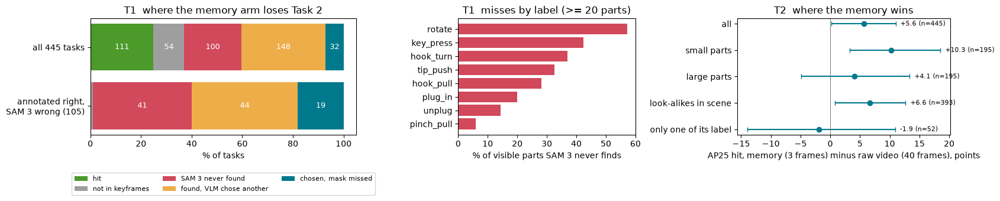

28 stage-0 numbers checked against the result files


In [18]:
S0 = ROOT / "runs" / "stage0"
t1 = json.loads((S0 / "task2_losses" / "summary.json").read_text())
t3 = H.run_json("t3_val30", "summary.json")
t5 = json.loads((S0 / "openeqa_fit" / "summary.json").read_text())

stage_names = {"hit": "hit", "not_in_keyframes": "not in keyframes", "never_found": "SAM 3 never found",
               "not_chosen": "found, VLM chose another", "lost_in_mask": "chosen, mask missed"}
colours = ["#4c9a2a", "#9e9e9e", "#d1495b", "#edae49", "#00798c"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.5, 1, 1.2]})
for row, (title, counts) in enumerate([("all 445 tasks", t1["stages_memory_arm"]),
                                       ("105 tasks annotated maps get right", t1["lost_to_annotated"]["stages"])]):
    left, total = 0, sum(counts.values())
    for (stage, label), colour in zip(stage_names.items(), colours):
        width = 100 * counts[stage] / total
        axes[0].barh(row, width, left=left, color=colour, label=label if row == 0 else None)
        if width > 6:
            axes[0].text(left + width / 2, row, f"{counts[stage]}", ha="center", va="center", color="white", fontsize=9)
        left += width
axes[0].set_yticks([0, 1], ["all 445 tasks", "annotated right,\nSAM 3 wrong (105)"]); axes[0].invert_yaxis()
axes[0].set_xlabel("% of tasks"); axes[0].legend(fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.55), ncol=3)
axes[0].set_title("T1  where the memory arm loses Task 2")
labels_cmp = t1["predictions"]["T1-P3"]["labels_compared"]
order = sorted(labels_cmp, key=labels_cmp.get)
axes[1].barh(order, [100 * labels_cmp[k] for k in order], color="#d1495b")
axes[1].set_xlabel("% of visible parts SAM 3 never finds"); axes[1].set_title("T1  misses by label (>= 20 parts)")
strata = [("all", "all"), ("small", "small parts"), ("large", "large parts"), ("several_of_label", "look-alikes in scene"),
          ("one_of_label", "only one of its label")]
for i, (key, name) in enumerate(strata):
    s = t1["memory_minus_raw"][key]
    axes[2].errorbar(s["diff"], i, xerr=[[s["diff"] - s["low"]], [s["high"] - s["diff"]]], fmt="o", color="#00798c", capsize=3)
    axes[2].text(s["high"] + 0.8, i, f'{s["diff"]:+.1f} (n={s["tasks"]})', va="center", fontsize=8)
axes[2].axvline(0, color="grey", lw=0.8); axes[2].set_yticks(range(len(strata)), [n for _, n in strata]); axes[2].invert_yaxis()
axes[2].set_xlabel("AP25 hit, memory (3 frames) minus raw video (40 frames), points"); axes[2].set_title("T2  where the memory wins")
plt.tight_layout(); plt.show()

g, og = t3["variants"]["lidar/gravity/best"], t3["variants"]["lidar/oracle_gravity/best"]
s0_checks = [
    check("T1 hit", t1["stages_memory_arm"]["hit"], 111), check("T1 not in keyframes", t1["stages_memory_arm"]["not_in_keyframes"], 54),
    check("T1 never found", t1["stages_memory_arm"]["never_found"], 100), check("T1 not chosen", t1["stages_memory_arm"]["not_chosen"], 148),
    check("T1 lost in mask", t1["stages_memory_arm"]["lost_in_mask"], 32), check("T1 lost to annotated", t1["lost_to_annotated"]["tasks"], 105),
    check("T1 lost: not chosen", t1["lost_to_annotated"]["stages"]["not_chosen"], 44),
    check("T1 lost: never found", t1["lost_to_annotated"]["stages"]["never_found"], 41),
    check("T1 lost: mask", t1["lost_to_annotated"]["stages"]["lost_in_mask"], 19),
    check("T1 spread", round(100 * t1["predictions"]["T1-P3"]["spread"]), 51),
    check("T2 all", round(t1["memory_minus_raw"]["all"]["diff"], 1), 5.6), check("T2 small", round(t1["memory_minus_raw"]["small"]["diff"], 1), 10.3),
    check("T2 several", round(t1["memory_minus_raw"]["several_of_label"]["diff"], 1), 6.6),
    check("T3 not seen", t3["counts"]["not_seen"], 78), check("T3 scored", t3["counts"]["scored"], 471),
    check("T3 gravity +MA", g["all"]["ma"], 48.8), check("T3 gravity +MAO", g["all"]["mao"], 38.4),
    check("T3 oracle_gravity +MA", og["all"]["ma"], 71.5), check("T3 oracle_gravity +MAO", og["all"]["mao"], 53.9),
    check("T3 door axis", og["off_part_rotations"]["ma"], 82.5), check("T3 door origin", og["off_part_rotations"]["mao"], 24.5),
    check("T5 flagged %", round(100 * t5["table"]["all"]["all"]["share"], 1), 12.9),
    check("T5 corrected focus %", round(100 * t5["focus_corrected_share"], 1), 15.1),
    check("T3 label-only +M (c1)", t3["variants"]["lidar/c1/best"]["all"]["m"], 74.3), check("T3 gravity +M", g["all"]["m"], 68.4),
]
carry = json.loads((ROOT / "runs" / "mem_phase1" / "tool_maps_summary.json").read_text())["tools"]["sam3"]["carry_ceiling"]
s0_checks += [check("found on some keyframe %", round(100 * carry["found_anywhere"]["rate"], 1), 74.4),
              check("shown to the VLM %", round(100 * carry["coverage"]["rate"], 1), 58.7),
              check("carry gain points", round(100 * carry["carried_minus_coverage"]["rate"], 1), 3.1)]
print(f"{len(s0_checks)} stage-0 numbers checked against the result files")

## 6.2 重新分析：框架的几个决定，我的推荐

**A. v3 是否正式作为主线：推荐采用，并冻结接口。**
- 30 个场景上，给定部件时，向量的 +MA 是 48.8、+MAO 是 38.4，高于唯一公开参照（训练过的模型）的粗折算。
- 记忆在预测的地方赢了直接看原视频：小部件 +10.3，场景里有同类部件 +6.6，而且只读 3 帧。
- "两个头读同一份部件表"的设计，没有哪项结果推翻它。

**决定 2：每个部件存不存"装在什么上"：推荐 (a) 存，证据比上次更强。**
- 类型是向量最大的误差：类型给对以后，+MA 从 48.8 升到 71.5，多了 22.7 个点。
- 靠几何猜"门还是抽屉"，类型反而比只看标签更差（+M 68.4 对 74.3）。
- "装在什么上"正是用来定类型的。它还顺带记下部件属于哪个物体（门、抽屉、柜子），按物体搜就是按这个字段搜。

**决定 3 和 6：affordance map 的形式。推荐 3 选 (a)：以逐部件的记录为核心，再加一个"可见性列表"字段。整屋的三维表面图（决定 6）先不做，留作阶段 5 的候选创新点。**
- 三维表面图对"搜索"最实在的好处，是按"哪一帧看得清"来挑帧。T1 里"找到了但没选中"是最大的一类损失，其中一部分就是目标所在的帧没被挑出来给 VLM 看：SAM 3 在某张帧上找到目标的任务占 74.4%，但被挑出来给 VLM 看到的只有 58.7%。这件事只要给每个部件存一个列表就能做：在哪些帧里看得见、有多大、离多远、正不正。不需要融合整屋的表面。
- 三维表面图解决不了另外两类损失：
  - SAM 3 在所有帧里都没找到（22.5% 的任务）。把找到的部件带到别的视角，覆盖只多 3.1 个点；要靠提示词和检测来补，漏得最多的是转的旋钮、按键和门把手。
  - 目标根本不在 40 张关键帧里（12.1% 的任务）。要回到原视频里去找帧。
- 现在的候选 bench（Task 2、Task 3、OpenEQA 的部件题）都用不到整屋几何。只有 VSI 那类空间题用得到，而它不考 affordance。
- 这样也不用推翻 11-11 第 3 轮"不融合稠密几何"的决定。
- **这和你 11-20 提的三维表面图想法有出入，需要你确认。** 我的建议是：它的核心好处（按可见性挑帧）现在就以"可见性列表"的形式放进框架；整屋表面图本身，等阶段 3 看挑帧是不是仍是瓶颈，或者要做"站不站得过去、门开不开得开"这类可行性问题时，再按事先写定的检验加上去。

**决定 5（公开评测落后以后怎么走）：诊断已经做完（T1）。推荐接受现在落后，先不花 GPU。**
到阶段 5 再按 T1 的分解定改进的顺序：
1. 读取：挑帧和选部件，占差距的 42%；
2. 几类标签的漏检，占 39%；
3. 掩码，占 18%。

**决定 1（服务器上用门板掩码、问 VLM"装在什么上"）和决定 4（S0d）：推荐都并进阶段 2 的跑通。**
- W4 最简单的真实版本，就是问 VLM"装在什么上"。方案先写好给你看，即决定 1 选 (a)。
- S0d 要的接触点和失败归类指标，并进 Task 3 的打分代码。

## 6.3 bench 适配表（初步；阶段 3 会用真实输入再测一遍）

| bench 或指标 | 适配 | 依据 | 我们的数据现在多强 |
| --- | --- | --- | --- |
| SceneFun3D Task 3（自己实现 OPD 式的指标），另按 AffordBot 的口径比一次 | **适合，最可能是主卖点** | T3、T4 | 给定部件时高于参照；没有现成的对手数字，要自己算 |
| 联合指标：部件找对并且动作对 | **适合，只有我们能报** | 同一批任务两种标注都有 | 还没测 |
| SceneFun3D Task 2 | 适合，是"找部件"唯一有公开对手的比较，但现在落后 | T1 | 落后 UniFunc3D 8B 19.1 个点，差距已分解 |
| 读得少（M2，Task 2 上 3 帧对 40 帧） | **适合** | T2 | +5.6；小部件 +10.3 |
| OpenEQA | 只当辅助 | T5 | 部件题约 15%，多是开关状态 |
| VSI-Bench | 不适合：不考 affordance | — | — |
| OPDMulti | 没测；输入是单张图，可以作为动作向量的补充 | — | — |

## 6.4 如果你同意，框架冻结时要改的接口

部件记录加两个字段：
- **装在什么上：** 门、抽屉、固定面板、翻盖等；
- **可见性列表：** 帧、面积、距离、角度。

如果要做 OpenEQA 的部件题，再加一个可选字段：**看到时的状态**（开或关）。其余接口不变。

## 6.5 主旨核对

| 你的主旨 | 阶段 0 |
| --- | --- |
| M1 可解释的三维向量 | **符合。** 30 个场景上给定部件时，向量高于公开参照 |
| M2 帮忙挑关键帧 | **符合。** 记忆在小部件、相似部件多时赢原视频；可见性列表是具体做法 |
| M3 affordance 加深度算出动作向量 | **符合。** T3；最大的误差是类型，靠"装在什么上"补 |
| M4 两个头 | **部分。** 问答头还没做；OpenEQA 只能当辅助，问答头要另找能体现部件的题 |
| M5 不训练 | **符合** |
| M6 资源少 | **符合。** 阶段 0 全部只用 CPU |

**和你的想法有出入的一处：** 决定 6 我推荐暂缓整屋三维表面图（理由见 6.2），需要你确认。（你的答复和后续讨论见第 7 节。）

---
# 7. 你对决定 1 到 6 的答复，以及决定 3、6 的讨论：一个场景一张图（11-20）

## 7.1 你的答复（原话）

"1 同意；2 存；3 需要讨论，逐个部件的记录会随着时间增常增大幻觉风险，我希望是一个隐性的features map一样的东西，一个场景只有一个大的map，之后在更新的时候可以通过环境相似度来定位大致位姿，然后细节的feature affordance可以直接用新的覆盖旧的，这样之后在查找对应的部件的时候仍然只有一个map的内容，但是他是最新的，帮我讨论一下这个是不是现实的，以及有没有过往研究做过相似的内容；4 加；5 同意，但是目前仍旧是pipeline的讨论，确定之后可以在使用GPU统一开始效果的追平；6 根据我第3点的回复同时讨论，给我你的看法以及其他相关的研究，如果没有整屋的affordance map的话，其他的pipeline又是怎么解决的呢，给我一些提示和建议，我可以在考虑如何去做，我个人比较不喜欢树形结构然后把所有信息存诚text格式的，这种格式本质上非常冗余且可能产生幻觉"

**我的理解：**

| 决定 | 你的答复 | 接下来 |
| --- | --- | --- |
| 1 服务器上分门板、问"装在什么上" | 同意 | 并进阶段 2 |
| 2 存"装在什么上" | 存 | 进接口 |
| 3 记忆用什么形式 | 要讨论：你想要一个场景一张特征图，不要逐个部件的记录 | 本节 7.2 到 7.8 |
| 4 抓握方向、接触区域和新指标 | 加 | 并进阶段 2 |
| 5 Task 2 落后 | 接受；pipeline 定了以后再统一用 GPU 追平 | 现在不花 GPU |
| 6 整屋三维表面图 | 和第 3 条一起讨论 | 本节 |

"v3 正式作为主线"这一条你没有单独答。第 3 条要改记忆的形式，所以我先不冻结；写入的五块和两个头先不动，等第 3、6 条定了再一起冻结。

## 7.2 先说结论

**你的想法是现实的。** 和我原来推荐的"逐个部件的记录"比，它有一个实在的好处：**能搜还没被认出来的东西。** 阶段 0 的测试 1 里，SAM 3 从没找到的 41 条任务，在逐部件记录里根本不存在；在一张特征图里，问题来了以后还能用任务里的词到图上去找。

要用起来，有三处需要改：
1. **"隐性"的做法：** 建议用"三维小格子，每格挂一个特征向量"，不用神经网络场或高斯场。后者每个场景都要先拟合几分钟到一个多小时，等于逐场景训练，和"不训练"冲突，局部改写也难。
2. **"新的覆盖旧的"：** 不能直接覆盖（7.4 有模拟的数）。要"新画面里看得见、看得清，而且几何上确实变了"才覆盖。
3. **幻觉：** 一张图本身不会胡编，胡编出在"谁来读、读什么"这一步。图要负责给出"在哪、哪几帧看得最清楚"，让 VLM 看原图，不看文字。

另外说明一点：原来的逐部件记录是按三维位置合并的，同一个部件只有一条，不会随时间无限增长。真正越积越多的是按时间追加的文字日志（ReMEmbR 报告过重复条目会稀释数据库）。所以我认同换成一张图，但理由主要是"能搜没认出来的东西"和"天然是最新的"，而不是记录数会涨。

## 7.3 你的想法拆成四件事，逐件看

| 你的想法 | 现实吗 | 已有的做法 | 要注意的 |
| --- | --- | --- | --- |
| 一个场景一张图，存特征，不存文字 | 现实 | **二维格子：** VLMaps（每格存 LSeg 特征）。**点或体素：** ConceptFusion（每点存 CLIP 特征），OK-Robot（5 cm 体素），DynaMem（体素存 SigLIP 特征、看见次数、来自哪张图、最后看见的时间）。**神经场或高斯：** LERF、LangSplat、Feature 3DGS | 神经场或高斯每个场景要拟合：LERF 约 45 分钟，LangSplat 约 25 分钟，Feature 3DGS 7 分钟到 1.5 小时。体素挂特征不用训练 |
| 靠环境相似度定大致位姿 | 现实，工具成熟 | 先用 AnyLoc 找出最像的旧画面（不训练，只给"是哪儿"不给位姿），再用 Reloc3r 或 MASt3R 算出位姿（不训练；Reloc3r 在 7-Scenes 上中位误差 4 cm、1°）。ACE 也很准，但每个场景要拟合约 5 分钟 | 定位错了会改错地方。要先检查配准是否可靠，不可靠就不改 |
| 细节的 feature affordance 新的覆盖旧的 | 方向对，但不能直接覆盖 | DynaMem：新深度图显示某个位置前面是空的（东西真的不在了）才删；Khronos：60% 以上的光线穿过一个物体才算它没了；Panoptic Multi-TSDFs：按几何是否一致判断物体还在不在 | 见 7.4：场景不变时直接覆盖也会误擦 10% 到 17% 已经找到的部件。另外，已有的更新都以整个物体为单位，没有做到部件这么细 |
| 查找时只读一张最新的图 | 现实 | 查找就是"问题文字对每格特征算相似度"，像 VLMaps、OK-Robot | 小部件和组合说法是弱项：LERF 分不清"杯子的把手"和"把手"；LERF-TOGO 显示 ConceptFusion 找不到物体上的部件。所以图只负责给候选位置和最好的帧，最后仍要 VLM 看原图来挑 |

## 7.4 "新的覆盖旧的"：用已有结果做的模拟

用阶段 0 的同一批输入（30 个验证场景，每个场景一段视频、40 张关键帧，SAM 3 部件图）。同一段视频里场景没有变化，所以任何"擦掉"都是误擦。这是事后的描述性统计，没有事先写预测；配置写明了这一点（`configs/stage0/overwrite_sim.yaml`）。

In [19]:
ow = json.loads((ROOT / "runs" / "stage0" / "overwrite_sim" / "summary.json").read_text())
pct = lambda x: f"{100 * x:.1f}%"
table = pd.DataFrame([
    ["部件在某帧里看得见时，SAM 3 在这一帧找到它", pct(ow["per_frame_found_rate"]), f"全部 {ow['parts']} 个部件"],
    ["同上，只看找到过的部件", pct(ow["per_frame_found_rate_ever_found"]), f"{ow['ever_found']} 个"],
    ["最新一帧说了算：找到过的部件被擦掉", pct(ow["erased"]["last_view"]["all"]), f"{ow['ever_found']} 个"],
    ["同上，只看至少出现在 2 张关键帧里的", pct(ow["erased"]["last_view"]["shown_twice_or_more"]), f"{ow['ever_found_shown_twice_or_more']} 个"],
    ["看得最大的一帧说了算：找到过的部件被擦掉", pct(ow["erased"]["largest_view"]["all"]), f"{ow['ever_found']} 个"],
], columns=["量", "数", "分母"])
display(table.style.hide(axis="index"))

量,数,分母
部件在某帧里看得见时，SAM 3 在这一帧找到它,66.2%,全部 481 个部件
同上，只看找到过的部件,80.9%,360 个
最新一帧说了算：找到过的部件被擦掉,14.4%,360 个
同上，只看至少出现在 2 张关键帧里的,17.2%,303 个
看得最大的一帧说了算：找到过的部件被擦掉,10.3%,360 个


**读法：**
- 一个部件明明在画面里，SAM 3 在单独一帧里只有约三分之二的机会找到它。所以"新一帧没看到"多数时候不是东西没了，而是这一帧没检出来。
- 如果最新一帧说了算，已经找到的部件会被误擦 14.4%；在至少出现两次的部件里是 17.2%。改成"看得最大的一帧说了算"也还有 10.3%。
- 所以覆盖要有条件：

| 情况 | 怎么改图 |
| --- | --- |
| 这一格在新画面里看得见、离得近、正对着，而且几何变了（深度显示东西移走了、门开了） | 用新的覆盖 |
| 看得见，但几何没变，只是这次没检出 | 保留旧的，记下"最后一次确认的时间" |
| 在新画面里看不见 | 不动 |

这样整张图仍然只有一份，而且是"最新确认过的"。

## 7.5 别人没有整屋 affordance 图时，是怎么"找"的

| 做法 | 代表工作 | 怎么找 | 卡在哪 |
| --- | --- | --- | --- |
| **文字的图或树**（你不喜欢的） | ConceptGraphs、OpenFunGraph（CVPR 2025，部件级）、FunGraph、Embodied-RAG、ReMEmbR | LLM 读每个节点的文字描述 | 描述错了、或部件当初没检出，就再也找不回（原图已经丢了）；部件在裁出的小图里只有几个像素，很难描述准；FunGraph 会把旋钮挂到错的物体上。OpenEQA 上，GPT-4 读 ConceptGraphs 的文字描述得 36.5，几乎等于不看场景的 33.5；直接看画面的 GPT-4V 得 55.3 |
| **存画面** | 3D-Mem（CVPR 2025）、Memory Over Maps（2026）、GSMem（2026） | 记住带位姿的画面，问题来了让 VLM 重看挑出来的几张 | 小部件在存下的分辨率里看不清；会挑错画面；3D-Mem 假设场景不变。3D-Mem 在 A-EQA 上 52.6，读 ConceptGraphs 文字的做法是 34.4 |
| **每个问题重看一遍视频** | Fun3DU、UniFunc3D、AffordBot（SceneFun3D 上的主要对手） | 每个问题从头找 | 慢（UniFunc3D 报告每题约 99 秒，用 8 张 H100）；没有记忆，也就没有跨次更新 |
| **稠密特征图**（你的方向） | VLMaps、ConceptFusion、OK-Robot、DynaMem、LERF 一类 | 问题文字对每格特征算相似度 | 多数只做到物体级；小部件和组合说法弱；除 DynaMem 外基本不更新，而且多是"平均"，不是"新的说了算" |

**能借鉴的几条：**
1. **存像素的索引，不存文字。** 文字是二手的，错了无法回头；画面是一手的。图里每格记下"哪些帧看见过它"，读的时候回到原图。
2. **删东西要靠几何证据。** DynaMem 和 Khronos 都是"光线穿过了、深度显示空了"才删，不靠"这一帧没检出来"。
3. **定位用"检索 + 两两算位姿"，不训练。** AnyLoc 找最像的旧画面，Reloc3r 或 MASt3R 算位姿。
4. **部件太小，特征格子分不清。** 细的东西要单独存，不能只靠特征相似度。
5. **运动方向别从单张图的模型里直接拿。** Splat-MOVER 把 VRB 的运动方向放进图里时嫌太噪，最后没存；我们用"装在什么上"加规则算。

## 7.6 最接近你想法的工作，以及它们都没做的事

| 工作 | 和你的想法像在哪 | 不一样在哪 |
| --- | --- | --- |
| DynaMem（2411.04999）；Dynamic Resilient Spatio-Semantic Memory（2606.00576） | 不训练；体素挂特征；新深度图和旧格子矛盾就删 | 物体级；后者每次从空图开始，不回到旧图 |
| DGSG-Mind（2605.29879）、3DGS-CD（2411.03706）、CL-Splats（ICCV 2025） | 先定位回旧图，再只改变了的地方 | 都要逐场景拟合；以整个物体为单位改 |
| FOCUS（2610.05639） | 每次回来比对，给每个物体记"还在 / 换了 / 没了" | 位姿要事先给定；物体级 |
| IAAO（CVPR 2025） | 特征场里有部件、affordance 和转轴 | 要两次完整扫描（动之前、动之后）和逐场景拟合 |
| Splat-MOVER（CoRL 2024） | 图里存了"哪里能抓" | 运动方向没存（作者嫌太噪）；要逐场景拟合 |

**都没做的事：** 一张不训练的、整个房间的稠密特征图，下次来的时候靠外观定位回去，在比物体更细的部件层面局部更新，并且图里存着"每个部件怎么动"。这正好是一个空位，可以作为论文的贡献点之一。

以上信息由两个检索代理逐篇核对过 arXiv 摘要或正文。会议没核实到的我没写会议名。

## 7.7 我的建议：决定 3 和 6 合成一个设计，一个场景一张两层的图

**一张图，每个格子有两层内容：**

| 层 | 存什么 | 给谁用 | 对应你的主旨 |
| --- | --- | --- | --- |
| 底层（找东西、定位） | 房间表面切成 2 到 5 cm 的格子。每格存：现成模型算出的特征向量（不训练）；哪些帧看见过它、看得多大多正；最后一次确认的时间 | 搜索、挑帧、定位 | 你说的"隐性的 features map"；M2 |
| 上层（动作） | 部件所在的格子上挂 affordance 向量：类型、方向或转轴、原点、接触点、抓握方向、装在什么上 | 动作头，直接给机器人 | 11-18 你说的"可解释的量"（E1）；M1、M3 |

**更新：** 新视频 → 找最像的旧画面、算位姿 → 配准可靠才改 → 按 7.4 的三种情况改格子。

**查找：** 问题文字 → 在底层上算相似度，得到候选位置 → 用"哪些帧看见过这里"挑最清楚的 2 到 3 帧 → VLM 看这几帧原图选出部件 → 从上层读出向量。全程没有文字记录，也没有树。

**为什么要两层：** 2 到 5 cm 的特征格子分不清 2 到 3 cm 的旋钮，所以细节放在上层、按部件存，查的时候再回到原图。

**代价（粗估）：**
- 每段视频要用 GPU 算一次特征（40 张关键帧）；
- 存储：设一个房间表面 100 平方米、3 cm 格子，约 11 万格；每格 768 维半精度约 1.5 KB，合计约 170 MB，压到 64 维约 14 MB。

## 7.8 建议的检验（放进阶段 2，等你点头）

1. **覆盖规则：** 把 7.4 的模拟改成"有条件覆盖"，看误擦能不能降到接近 0（CPU）。
2. **第二次来：** SceneFun3D 的 30 个验证场景，每个场景有 2 到 3 段视频，共 82 段，每段都带对齐到同一份激光扫描的真值矩阵。服务器上现在每个场景只下了 1 段，另外 52 段要下载；按现在的下法每段约 0.1 GB，磁盘够用。
   - 先用真值对齐：第二段视频能补上第一段漏掉的多少部件，有条件覆盖会误擦多少；
   - 再换成相似度定位：位姿误差够不够用。
3. **找回从没认出来的部件：** 在底层特征图上直接用任务里的词去查，看测试 1 里 SAM 3 从没找到的 41 条能找回几条（每段视频算一次特征，用 GPU 队列）。

## 7.9 要你决定的事

1. **记忆的形式：**
   - (a) 一个场景一张两层的图：底层格子挂特征（不训练），上层在部件处挂可解释的向量（推荐）；
   - (b) 纯神经场或高斯场：更"隐性"，但每个场景要拟合几分钟到一个多小时，等于逐场景训练；
   - (c) 先保留逐部件记录，图以后再加。
2. **覆盖规则：**
   - (a) 有条件覆盖：看得见、看得清、几何变了才改（推荐）；
   - (b) 直接新的覆盖旧的：场景不变时也会误擦 10% 到 17%。
3. **"第二次来"的检验：**
   - (a) 下载另外 52 段视频，放进阶段 2（推荐）；
   - (b) 先只在单段视频上做。
4. **"隐性"和"可解释"怎么合：**
   - (a) 底层是隐性特征，上层是可解释向量（推荐）；
   - (b) 全部存隐性特征，机器人要的向量在查的时候从特征里现算。

你答完以后，我把新的记忆形式画进 pipeline 图，然后冻结框架（阶段 1），再进阶段 2。

## 7.10 主旨核对

| 你的主旨 | 这次的讨论 |
| --- | --- |
| M1 可解释的三维向量 | **符合**：上层就是可解释的三维向量 |
| M2 帮忙挑关键帧 | **符合，而且更直接**：每格记着哪些帧看见过它 |
| M3 affordance 加深度算出动作向量 | **符合** |
| M4 两个头 | **部分**：问答头读的是图挑出的原图，开放式问答还没做。"最新的图"能回答"门开着吗"这类状态题，正好是 OpenEQA 里多数部件题 |
| M5 不训练 | **符合**，前提是 1 选 (a)；选 (b) 就是偏移 |
| M6 资源少 | **基本符合**：每段视频算一次特征，一个房间约百 MB；要下载 52 段视频 |

**出入：** 你这次说的"隐性的 features map"，和 11-18 说的"可解释的量，不是学出来的特征"（E1）不一样。我记进了《理解差异记录》第 7 条，推荐用两层把两者合起来（第 4 题）。

## ✏️ 你的批注

这一周的意见和更新写在这一格里，我读到以后逐条回复。上一周的 pipeline 工作文档已并入第 1 周 notebook 第 8 部分；以后的批注都写在当周 notebook 的这一格里。

（空）

---
# 附录

## A. 命令（都在仓库根目录，服务器上跑；除公开评测的 GPU 一步外都只用 CPU）

| 内容 | 命令 |
| --- | --- |
| S0、S0b、S0c | `python scripts/run_part_vectors.py --config configs/part_vectors/<s0_421069 / s0b_val3 / s0c_gravity_val3>.yaml` |
| 门窗诊断 | `python scripts/diagnose_door_hinges.py --config configs/part_vectors/<s0b_val3 / s0c_gravity_val3>.yaml` |
| 演示用的向量（场景 421069） | `python scripts/run_part_vectors.py --config configs/part_vectors/demo_421069_gravity.yaml` |
| 两个视频 | `python scripts/make_week2_media.py --config configs/report/week2_media.yaml` |
| 标签和运动类型、部件形状 | `python scripts/count_label_motions.py --scenes third_party/scenefun3d/benchmark_file_lists/val_scenes.txt`；`count_part_shapes.py` 同样的参数 |
| 公开评测 | `python scripts/run_public_eval.py --config configs/public_eval/split0_8b.yaml --stage <queue / lift / score --official>` |
| 阶段 0（第 6 节） | `python scripts/diagnose_task2_losses.py --config configs/stage0/task2_losses.yaml`；`python scripts/run_part_vectors.py --config configs/part_vectors/t3_val30.yaml`；`python scripts/openeqa_fit.py --config configs/stage0/openeqa_fit.yaml --stage <count / correct>` |
| 覆盖模拟（第 7 节） | `python scripts/simulate_overwrite.py --config configs/stage0/overwrite_sim.yaml` |
| 这份 notebook | `python notebooks/builders/build_report_2026_11_20_week2.py report/week2_2026-11-16_to_11-22.ipynb`，再用 `jupyter nbconvert --to notebook --execute --inplace` 执行 |

**文档：** 推荐 pipeline 和三轮检验 `docs/mem/新pipeline_差异_文献_推荐_2026-11-18.md`；理解差异 `docs/mem/理解差异记录.md`；实验索引 `EXPERIMENTS.md`。

## B. 数字核对

正文里引用的数字，下面逐个从结果文件里重新算一遍；对不上时这一格会报错。

In [20]:
s0b_doors = H.run_json("s0b_val3", "door_hinges.json")["counts"]["lidar"]
checks = [
    check("S0c parts", s0c["counts"]["elements"], 80), check("S0c scored", s0c["counts"]["scored"], 64),
    check("S0c never in keyframes", s0c["counts"]["not_seen"], 12),
    check("S0c true door axes vertical", doors["true_axis_vertical"], 16), check("S0c doors", doors["doors"], 19),
    check("S0c oracle_kind door +MA %", round(off["oracle_kind"]["ma"]), 68), check("S0c oracle_gravity door +MA %", round(off["oracle_gravity"]["ma"]), 84),
    check("S0c oracle_kind door +MAO %", round(off["oracle_kind"]["mao"]), 16), check("S0c oracle_gravity door +MAO %", round(off["oracle_gravity"]["mao"]), 21),
    check("S0b doors", s0b_doors["doors"], 44), check("S0b true axes vertical", s0b_doors["true_axis_vertical"], 42),
    check("S0b old rule axis right", s0b_doors["rule"]["axis_ok"], 21), check("S0b vertical+handle axis right", s0b_doors["up_handle"]["axis_ok"], 39),
    check("S0b side given, axis+origin", s0b_doors["up_right_end"]["axis_and_origin_ok"], 21),
    check("label-only ceiling %", round(100 * best / sum(pairs.values()), 1), 80.3),
    check("walkthrough frames", media["walkthrough"]["frames"], 1025),
    check("oracle_chosen AP25", round(pe["means"]["oracle_chosen"]["AP25"], 1), 51.5),
    check("overwrite parts", ow["parts"], 481), check("overwrite ever found", ow["ever_found"], 360),
    check("overwrite per-frame found %", round(100 * ow["per_frame_found_rate"], 1), 66.2),
    check("overwrite per-frame found, ever-found %", round(100 * ow["per_frame_found_rate_ever_found"], 1), 80.9),
    check("overwrite last view erases %", round(100 * ow["erased"]["last_view"]["all"], 1), 14.4),
    check("overwrite last view erases, shown twice+ %", round(100 * ow["erased"]["last_view"]["shown_twice_or_more"], 1), 17.2),
    check("overwrite largest view erases %", round(100 * ow["erased"]["largest_view"]["all"], 1), 10.3),
]
mine = {rule: [r for r in rows_c if (r["depth"], r["rule"], r["frames"]) == ("lidar", rule, "best") and drawer(r)] for rule in ("c1", "geometric")}
checks += [check("S0c drawers", len(mine["c1"]), 35), check("S0c drawers right, label only", sum(r["score"]["m"] for r in mine["c1"]), 31),
           check("S0c drawers right, geometric", sum(r["score"]["m"] for r in mine["geometric"]), 20)]
print(f"{len(checks)} numbers checked, all match the result files")

27 numbers checked, all match the result files
